In [1]:
import os
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm

base_url = "https://physionet.org/files/challenge-2019/1.0.0/training/training_setA/"
output_dir = "./training/training_setA/"
os.makedirs(output_dir, exist_ok=True)

# Generate list of all 20,336 filenames (p000001.psv to p020336.psv)
print("generating file list...")
all_files = [f"p{i:06d}.psv" for i in range(1, 20337)]

def download_one_file(filename):
    save_path = os.path.join(output_dir, filename)
    # Skip if already exists (so you don't redownload the first 500)
    if os.path.exists(save_path) and os.path.getsize(save_path) > 0:
        return
    try:
        urllib.request.urlretrieve(base_url + filename, save_path)
    except Exception:
        pass # Skip errors for now

print(f" Starting Parallel Download of {len(all_files)} files...")

# ThreadPoolExecutor runs 20 downloads at once
with ThreadPoolExecutor(max_workers=20) as executor:
    list(tqdm(executor.map(download_one_file, all_files), total=len(all_files)))

generating file list...
 Starting Parallel Download of 20336 files...


100%|██████████| 20336/20336 [12:27<00:00, 27.22it/s]


Loading 3000 patients for train...
Created 1292 training windows of shape (1292, 48, 5)

📊 Class Distribution:
   Sepsis patients:     270 (679 windows)
   Non-sepsis patients: 2730 (613 windows)
   Imbalance ratio:     0.9:1

✓ Weighted Sampler Created:
   Non-sepsis weight: 1.0538
   Sepsis weight:     0.9514 (0.9x higher)
   Effect: ~50/50 balanced batches during training
   ✓ Vital-specific noise scaling ENABLED
   Initial scales: HR=1.0, MAP=1.2, O2Sat=0.3, SBP=1.1, Resp=0.8
Created 1292 training windows of shape (1292, 48, 5)

📊 Class Distribution:
   Sepsis patients:     270 (679 windows)
   Non-sepsis patients: 2730 (613 windows)
   Imbalance ratio:     0.9:1

✓ Weighted Sampler Created:
   Non-sepsis weight: 1.0538
   Sepsis weight:     0.9514 (0.9x higher)
   Effect: ~50/50 balanced batches during training
   ✓ Vital-specific noise scaling ENABLED
   Initial scales: HR=1.0, MAP=1.2, O2Sat=0.3, SBP=1.1, Resp=0.8

Starting Training...
📊 Using BALANCED sampling (sepsis patients 

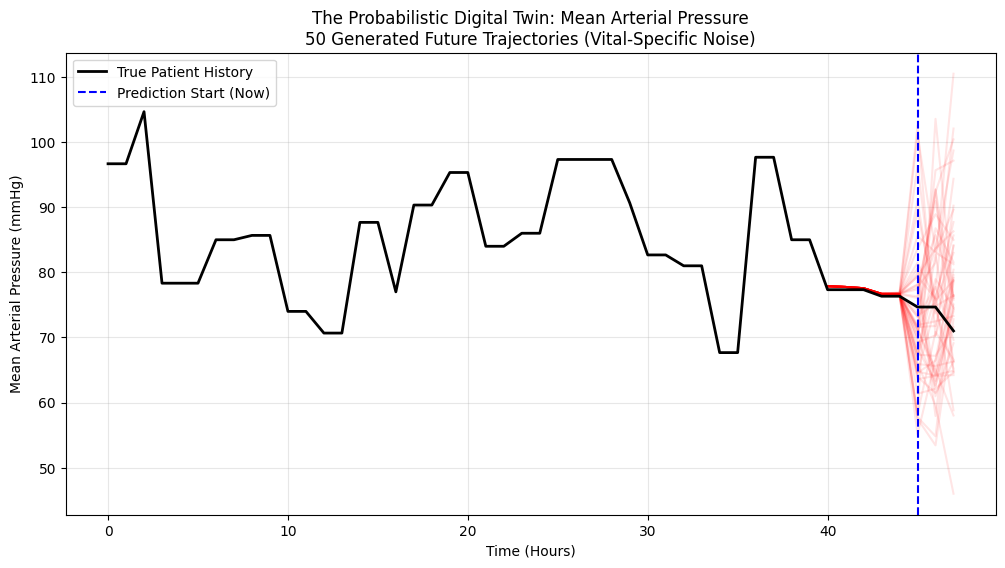


✓ Done! If you see a spread of red lines, that is the uncertainty envelope.
  With vital-specific noise, each vital now has calibrated uncertainty.


In [2]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import matplotlib.pyplot as plt
import math
from collections import Counter

# ==========================================
# 0. Configuration
# ==========================================
CONFIG = {
    "DATA_PATH": "./training/training_setA",  # Local folder (or update to your path)
    "VITALS": ['HR', 'MAP', 'O2Sat', 'SBP', 'Resp'],
    "SEQ_LEN": 48,      # Total window size (e.g., 48 hours)
    "PRED_LEN": 3,      # How many hours to predict into the future
    "BATCH_SIZE": 32,
    "HIDDEN_DIM": 128,
    "DIFFUSION_STEPS": 100,
    "EPOCHS": 30,       # Keep low for MVP presentation
    "MAX_FILES": 3000,  # Limit dataset size for speed (MVP mode)
    "USE_BALANCED_SAMPLING": True,  # Enable weighted sampling for class balance
    "USE_VITAL_SPECIFIC_NOISE": True  # NEW: Enable per-vital noise scaling
}

# Vital sign display info with natural variability estimates
VITAL_INFO = {
    'HR': {'name': 'Heart Rate', 'unit': 'bpm', 'scale': 100, 'variability': 1.0},
    'MAP': {'name': 'Mean Arterial Pressure', 'unit': 'mmHg', 'scale': 100, 'variability': 1.2},  # Higher variability
    'O2Sat': {'name': 'Oxygen Saturation', 'unit': '%', 'scale': 100, 'variability': 0.3},  # Low variability (stable)
    'SBP': {'name': 'Systolic Blood Pressure', 'unit': 'mmHg', 'scale': 140, 'variability': 1.1},
    'Resp': {'name': 'Respiratory Rate', 'unit': 'breaths/min', 'scale': 20, 'variability': 0.8}
}

# ==========================================
# 1. Dataset Loader (With Sepsis Tracking)
# ==========================================
class SepsisDataset(Dataset):
    def __init__(self, data_dir, config, mode='train'):
        self.files = sorted([f for f in os.listdir(data_dir) if f.endswith('.psv')])
        # MVP: Limit to first N files to save time
        self.files = self.files[:config["MAX_FILES"]]
        self.data_dir = data_dir
        self.vitals = config["VITALS"]
        self.seq_len = config["SEQ_LEN"]
        self.data_cache = []
        self.sepsis_flags = []  # Track sepsis status per window

        print(f"Loading {len(self.files)} patients for {mode}...")
        
        sepsis_patients = 0
        non_sepsis_patients = 0

        # Pre-load and process valid windows
        for f in self.files:
            df = pd.read_csv(os.path.join(data_dir, f), sep='|')
            
            # Check if patient developed sepsis
            has_sepsis = df['SepsisLabel'].max() == 1 if 'SepsisLabel' in df.columns else False
            
            if has_sepsis:
                sepsis_patients += 1
            else:
                non_sepsis_patients += 1

            # Select vitals
            df = df[self.vitals]

            # 1. Handle Missing Data (Crucial for Medical Time Series)
            df = df.ffill()
            df = df.bfill()
            df = df.fillna(0)

            # 2. Normalize
            norm_vals = {'HR': 100, 'MAP': 100, 'O2Sat': 100, 'SBP': 140, 'Resp': 20}
            for v in self.vitals:
                df[v] = df[v] / norm_vals[v]

            data = df.values.astype(np.float32)

            # 3. Create Sliding Windows
            if len(data) >= self.seq_len:
                for i in range(0, len(data) - self.seq_len + 1, 12): # Stride of 12
                    window = data[i : i + self.seq_len]
                    self.data_cache.append(window)
                    self.sepsis_flags.append(has_sepsis)

        self.data_cache = np.array(self.data_cache)
        self.sepsis_flags = np.array(self.sepsis_flags)
        
        # Print class distribution
        n_sepsis_windows = self.sepsis_flags.sum()
        n_non_sepsis_windows = len(self.sepsis_flags) - n_sepsis_windows
        
        print(f"Created {len(self.data_cache)} training windows of shape {self.data_cache.shape}")
        print(f"\n📊 Class Distribution:")
        print(f"   Sepsis patients:     {sepsis_patients} ({n_sepsis_windows} windows)")
        print(f"   Non-sepsis patients: {non_sepsis_patients} ({n_non_sepsis_windows} windows)")
        if n_sepsis_windows > 0:
            print(f"   Imbalance ratio:     {n_non_sepsis_windows/n_sepsis_windows:.1f}:1")

    def __len__(self):
        return len(self.data_cache)

    def __getitem__(self, idx):
        # Shape: (Seq_Len, Channels) -> Transpose to (Channels, Seq_Len) for PyTorch Conv1d
        sample = self.data_cache[idx]
        return torch.tensor(sample).transpose(0, 1)


# ==========================================
# 1.5 Weighted Sampler for Balanced Training
# ==========================================
def create_weighted_sampler(dataset):
    """
    Create a weighted sampler that oversamples sepsis patient windows.
    This helps the model learn both normal and deterioration patterns.
    """
    sepsis_flags = dataset.sepsis_flags
    class_counts = Counter(sepsis_flags)
    
    n_samples = len(sepsis_flags)
    n_sepsis = class_counts[True]
    n_non_sepsis = class_counts[False]
    
    # Calculate weights: inverse frequency
    weight_sepsis = n_samples / (2 * n_sepsis) if n_sepsis > 0 else 0
    weight_non_sepsis = n_samples / (2 * n_non_sepsis) if n_non_sepsis > 0 else 0
    
    # Assign weight to each sample
    weights = []
    for is_sepsis in sepsis_flags:
        if is_sepsis:
            weights.append(weight_sepsis)
        else:
            weights.append(weight_non_sepsis)
    
    weights = torch.tensor(weights, dtype=torch.float64)
    
    sampler = WeightedRandomSampler(
        weights=weights,
        num_samples=len(weights),
        replacement=True
    )
    
    print(f"\n✓ Weighted Sampler Created:")
    print(f"   Non-sepsis weight: {weight_non_sepsis:.4f}")
    print(f"   Sepsis weight:     {weight_sepsis:.4f} ({weight_sepsis/weight_non_sepsis:.1f}x higher)")
    print(f"   Effect: ~50/50 balanced batches during training")
    
    return sampler


# ==========================================
# 2. The Diffusion Model (With Vital-Specific Noise)
# ==========================================
class SinusoidalEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
    def forward(self, time):
        device = time.device
        half_dim = self.dim // 2
        embeddings = math.log(10000) / (half_dim - 1)
        embeddings = torch.exp(torch.arange(half_dim, device=device) * -embeddings)
        embeddings = time[:, None] * embeddings[None, :]
        embeddings = torch.cat((embeddings.sin(), embeddings.cos()), dim=-1)
        return embeddings

class ResidualBlock(nn.Module):
    def __init__(self, channels, time_emb_dim):
        super().__init__()
        self.conv1 = nn.Conv1d(channels, channels, 3, padding=1)
        self.conv2 = nn.Conv1d(channels, channels, 3, padding=1)
        self.time_mlp = nn.Linear(time_emb_dim, channels)
        self.bn = nn.BatchNorm1d(channels)
        self.act = nn.LeakyReLU(0.2)

    def forward(self, x, t):
        h = self.conv1(self.act(x))
        time_emb = self.time_mlp(self.act(t)).unsqueeze(-1)
        h = h + time_emb
        h = self.conv2(self.act(h))
        return self.bn(h + x)


class MedicalDiffusion(nn.Module):
    """
    Diffusion model with LEARNED per-vital noise scaling.
    This allows the model to adapt uncertainty to each vital's natural variability.
    """
    def __init__(self, num_channels, seq_len, hidden_dim=64, use_vital_specific_noise=True):
        super().__init__()
        self.num_channels = num_channels
        self.use_vital_specific_noise = use_vital_specific_noise
        self.time_emb = SinusoidalEmbedding(hidden_dim)

        # Input: Channels + Mask (Conditioning)
        self.input_proj = nn.Conv1d(num_channels * 2, hidden_dim, 1)

        self.res1 = ResidualBlock(hidden_dim, hidden_dim)
        self.res2 = ResidualBlock(hidden_dim, hidden_dim)
        self.res3 = ResidualBlock(hidden_dim, hidden_dim)
        self.res4 = ResidualBlock(hidden_dim, hidden_dim)

        self.output_proj = nn.Conv1d(hidden_dim, num_channels, 1)
        
        # NEW: Learnable per-vital noise scale parameters
        # These will be optimized during training to match each vital's variability
        if use_vital_specific_noise:
            # Initialize with prior knowledge about variability
            # [HR, MAP, O2Sat, SBP, Resp] -> [1.0, 1.2, 0.3, 1.1, 0.8]
            initial_scales = torch.tensor([1.0, 1.2, 0.3, 1.1, 0.8])
            self.vital_noise_scale = nn.Parameter(initial_scales)
            print(f"   ✓ Vital-specific noise scaling ENABLED")
            print(f"   Initial scales: HR={initial_scales[0]:.1f}, MAP={initial_scales[1]:.1f}, "
                  f"O2Sat={initial_scales[2]:.1f}, SBP={initial_scales[3]:.1f}, Resp={initial_scales[4]:.1f}")

    def get_noise_scale(self, detach=False):
        """Get the current noise scale for each vital (clamped to positive values)"""
        if self.use_vital_specific_noise:
            # Softplus ensures positive values, then scale
            scale = F.softplus(self.vital_noise_scale) + 0.1
            if detach:
                scale = scale.detach()
            return scale
        else:
            return torch.ones(self.num_channels)

    def forward(self, x, mask, t):
        # x: Noisy observation
        # mask: 1 for Observed (Past), 0 for Missing (Future)

        # Concatenate Input with Mask so model knows what is "Real" and what is "Hallucination"
        x_in = torch.cat([x, mask], dim=1)

        t_emb = self.time_emb(t)

        h = self.input_proj(x_in)
        h = self.res1(h, t_emb)
        h = self.res2(h, t_emb)
        h = self.res3(h, t_emb)
        h = self.res4(h, t_emb)

        return self.output_proj(h)


# ==========================================
# 3. Training & Inference Logic (With Vital-Specific Noise)
# ==========================================
def get_beta_schedule(steps):
    return torch.linspace(0.0001, 0.02, steps)


def train_model():
    dataset = SepsisDataset(CONFIG["DATA_PATH"], CONFIG)
    
    # Use weighted sampling if enabled
    if CONFIG["USE_BALANCED_SAMPLING"]:
        sampler = create_weighted_sampler(dataset)
        dataloader = DataLoader(dataset, batch_size=CONFIG["BATCH_SIZE"], sampler=sampler)
    else:
        dataloader = DataLoader(dataset, batch_size=CONFIG["BATCH_SIZE"], shuffle=True)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = MedicalDiffusion(
        len(CONFIG["VITALS"]), 
        CONFIG["SEQ_LEN"], 
        CONFIG["HIDDEN_DIM"],
        use_vital_specific_noise=CONFIG["USE_VITAL_SPECIFIC_NOISE"]
    ).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    betas = get_beta_schedule(CONFIG["DIFFUSION_STEPS"]).to(device)
    alphas = 1. - betas
    alphas_cumprod = torch.cumprod(alphas, dim=0)

    print("\nStarting Training...")
    if CONFIG["USE_BALANCED_SAMPLING"]:
        print("📊 Using BALANCED sampling (sepsis patients oversampled)")
    if CONFIG["USE_VITAL_SPECIFIC_NOISE"]:
        print("📊 Using VITAL-SPECIFIC noise scaling")
    model.train()

    for epoch in range(CONFIG["EPOCHS"]):
        total_loss = 0
        for batch in dataloader:
            batch = batch.to(device) # Shape: (B, Channels, Time)

            # Create Mask: Hide the last PRED_LEN hours (The "Future")
            mask = torch.ones_like(batch)
            mask[:, :, -CONFIG["PRED_LEN"]:] = 0

            # Get vital-specific noise scales (with gradients for training)
            noise_scale = model.get_noise_scale(detach=False).to(device)  # Shape: (num_channels,)
            noise_scale = noise_scale.view(1, -1, 1)  # Shape: (1, C, 1) for broadcasting
            
            # Generate noise with vital-specific scaling
            base_noise = torch.randn_like(batch)
            noise = base_noise * noise_scale  # Scale noise per vital
            
            t = torch.randint(0, CONFIG["DIFFUSION_STEPS"], (batch.shape[0],), device=device)

            alpha_bar = alphas_cumprod[t].reshape(-1, 1, 1)
            noisy_input = torch.sqrt(alpha_bar) * batch + torch.sqrt(1 - alpha_bar) * noise

            # IMPUTATION CONDITIONING:
            # The model sees: (Masked Real Data) + (Noisy Future)
            model_input = mask * batch + (1 - mask) * noisy_input

            # Predict
            pred_noise = model(model_input, mask, t)

            # Loss only on the FUTURE (the missing part)
            # Scale the loss by inverse noise scale to balance gradients
            loss = F.mse_loss(pred_noise * (1-mask), noise * (1-mask))

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        # Print learned noise scales every 10 epochs
        if (epoch + 1) % 10 == 0 and CONFIG["USE_VITAL_SPECIFIC_NOISE"]:
            scales = model.get_noise_scale(detach=True).cpu().numpy()
            scale_str = ", ".join([f"{v}={s:.2f}" for v, s in zip(CONFIG["VITALS"], scales)])
            print(f"Epoch {epoch+1}/{CONFIG['EPOCHS']} | Loss: {total_loss/len(dataloader):.5f} | Scales: {scale_str}")
        else:
            print(f"Epoch {epoch+1}/{CONFIG['EPOCHS']} | Loss: {total_loss/len(dataloader):.5f}")

    # Print final learned scales
    if CONFIG["USE_VITAL_SPECIFIC_NOISE"]:
        print("\n📊 Final Learned Noise Scales:")
        scales = model.get_noise_scale(detach=True).cpu().numpy()
        for v, s in zip(CONFIG["VITALS"], scales):
            print(f"   {v:6s}: {s:.3f}")

    return model, dataset


def generate_digital_twin(model, patient_data, device):
    """
    patient_data: (Channels, Time)
    Generates 50 possible futures for this patient.
    Uses vital-specific noise scaling during generation.
    """
    model.eval()
    n_samples = 50
    seq_len = patient_data.shape[1]

    # Repeat patient data 50 times
    x = patient_data.unsqueeze(0).repeat(n_samples, 1, 1).to(device)

    # Mask the future
    mask = torch.ones_like(x)
    mask[:, :, -CONFIG["PRED_LEN"]:] = 0

    # Get vital-specific noise scales (detached for inference - no gradients needed)
    noise_scale = model.get_noise_scale(detach=True).to(device).view(1, -1, 1)

    # Start with vital-scaled noise
    base_noise = torch.randn_like(x)
    curr_img = base_noise * noise_scale

    betas = get_beta_schedule(CONFIG["DIFFUSION_STEPS"]).to(device)
    alphas = 1. - betas
    alphas_cumprod = torch.cumprod(alphas, dim=0)

    with torch.no_grad():
        for t in reversed(range(CONFIG["DIFFUSION_STEPS"])):
            # Conditioning: Always reset the PAST to the known ground truth
            curr_img = mask * x + (1 - mask) * curr_img

            t_tensor = torch.full((n_samples,), t, device=device, dtype=torch.long)

            pred_noise = model(curr_img, mask, t_tensor)

            alpha = alphas[t]
            alpha_bar = alphas_cumprod[t]
            beta = betas[t]

            if t > 0:
                # Use vital-specific noise scaling
                z = torch.randn_like(curr_img) * noise_scale
            else:
                z = 0

            # DDPM update
            curr_img = (1 / torch.sqrt(alpha)) * (curr_img - ((1 - alpha) / torch.sqrt(1 - alpha_bar)) * pred_noise) + torch.sqrt(beta) * z

    return curr_img.cpu().numpy()


# ==========================================
# 4. Main Execution & Visualization
# ==========================================
if __name__ == "__main__":
    # Check if data exists
    if not os.path.exists(CONFIG["DATA_PATH"]):
        print("Error: Data path not found. Please run the download script first.")
    else:
        # Train
        model, dataset = train_model()

        # Pick a random patient sample
        idx = np.random.randint(0, len(dataset))
        patient_sample = dataset[idx] # (Channels, Time)

        print(f"\nGenerating Digital Twin Futures for patient {idx}...")
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        futures = generate_digital_twin(model, patient_sample, device) # (50, Channels, Time)

        # Visualizing 'MAP' (Mean Arterial Pressure) - Index 1 in VITALS list
        vital_idx = 1
        vital_key = CONFIG["VITALS"][vital_idx]
        vital_name = VITAL_INFO[vital_key]['name']

        plt.figure(figsize=(12, 6))

        # Plot 50 generated futures
        split_pt = CONFIG["SEQ_LEN"] - CONFIG["PRED_LEN"]

        # Un-normalize for display
        scale_factor = VITAL_INFO[vital_key]['scale']

        # Plot 50 Futures
        for i in range(50):
            plt.plot(range(split_pt-5, CONFIG["SEQ_LEN"]),
                     futures[i, vital_idx, split_pt-5:] * scale_factor,
                     color='red', alpha=0.1)

        # Plot Ground Truth
        truth = patient_sample[vital_idx] * scale_factor
        plt.plot(range(CONFIG["SEQ_LEN"]), truth, color='black', linewidth=2, label="True Patient History")

        # Visuals
        plt.axvline(x=split_pt, color='blue', linestyle='--', label="Prediction Start (Now)")
        plt.title(f"The Probabilistic Digital Twin: {vital_name}\n50 Generated Future Trajectories (Vital-Specific Noise)")
        plt.xlabel("Time (Hours)")
        plt.ylabel(f"{vital_name} ({VITAL_INFO[vital_key]['unit']})")
        plt.legend(loc='upper left')
        plt.grid(True, alpha=0.3)
        plt.show()

        print("\n✓ Done! If you see a spread of red lines, that is the uncertainty envelope.")
        print("  With vital-specific noise, each vital now has calibrated uncertainty.")

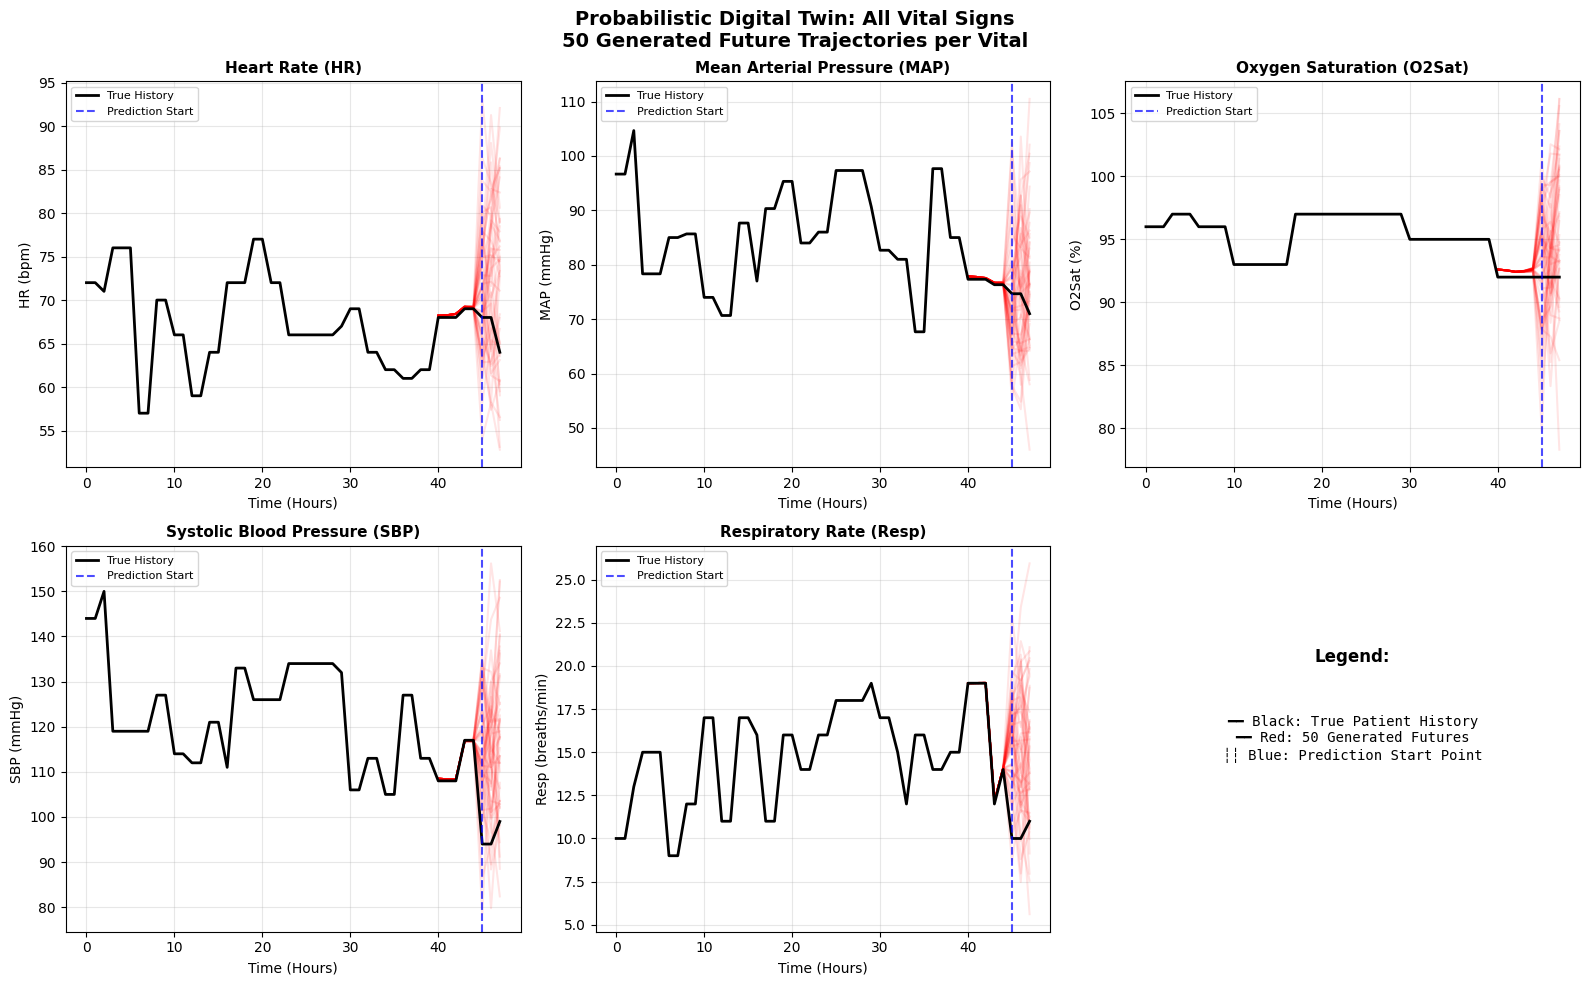


✓ Done! The spread of red lines shows uncertainty in future predictions.
  Wider spread = more uncertainty, Narrow spread = more confident prediction


In [3]:
# ==========================================
# 5. Visualize ALL 5 Vitals (Multi-Plot)
# ==========================================

# Make sure 'model', 'dataset', 'patient_sample', and 'futures' exist from previous cell
# If not, re-run the main cell first

split_pt = CONFIG["SEQ_LEN"] - CONFIG["PRED_LEN"]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for vital_idx, vital_key in enumerate(CONFIG["VITALS"]):
    ax = axes[vital_idx]
    info = VITAL_INFO[vital_key]
    scale_factor = info['scale']
    
    # Plot 50 generated futures (red, semi-transparent)
    for i in range(50):
        ax.plot(range(split_pt-5, CONFIG["SEQ_LEN"]),
                futures[i, vital_idx, split_pt-5:] * scale_factor,
                color='red', alpha=0.1)
    
    # Plot Ground Truth (black line)
    truth = patient_sample[vital_idx].numpy() * scale_factor
    ax.plot(range(CONFIG["SEQ_LEN"]), truth, color='black', linewidth=2, label="True History")
    
    # Prediction start line
    ax.axvline(x=split_pt, color='blue', linestyle='--', alpha=0.7, label="Prediction Start")
    
    # Labels
    ax.set_title(f"{info['name']} ({vital_key})", fontsize=11, fontweight='bold')
    ax.set_xlabel("Time (Hours)")
    ax.set_ylabel(f"{vital_key} ({info['unit']})")
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(True, alpha=0.3)

# Hide the 6th subplot (we have 5 vitals)
axes[5].axis('off')

# Add legend explanation in empty subplot
axes[5].text(0.5, 0.7, "Legend:", fontsize=12, fontweight='bold', 
             ha='center', transform=axes[5].transAxes)
axes[5].text(0.5, 0.5, "━━ Black: True Patient History\n"
                       "━━ Red: 50 Generated Futures\n"
                       "┆┆ Blue: Prediction Start Point",
             fontsize=10, ha='center', va='center', transform=axes[5].transAxes,
             family='monospace')

plt.suptitle("Probabilistic Digital Twin: All Vital Signs\n"
             "50 Generated Future Trajectories per Vital", 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n✓ Done! The spread of red lines shows uncertainty in future predictions.")
print("  Wider spread = more uncertainty, Narrow spread = more confident prediction")

In [4]:
# ==========================================
# 6. Quantitative Evaluation Metrics
# ==========================================

def evaluate_diffusion(model, dataset, device, n_eval=100):
    """
    Compute quantitative metrics for probabilistic forecasts.
    
    Metrics:
    - MAE: Mean Absolute Error of mean prediction
    - Coverage: % of ground truth within 90% prediction interval
    - CRPS-like: Continuous Ranked Probability Score approximation
    """
    model.eval()
    
    all_maes = []
    all_coverages = []
    all_interval_widths = []
    vital_maes = {v: [] for v in CONFIG["VITALS"]}
    vital_coverages = {v: [] for v in CONFIG["VITALS"]}
    
    indices = np.random.choice(len(dataset), min(n_eval, len(dataset)), replace=False)
    
    print(f"\n🔬 Evaluating on {len(indices)} samples...")
    
    for i, idx in enumerate(indices):
        if (i + 1) % 20 == 0:
            print(f"   Processing sample {i+1}/{len(indices)}...")
        
        patient_sample = dataset[idx]
        futures = generate_digital_twin(model, patient_sample, device)  # (50, C, T)
        
        # Ground truth for the prediction window
        truth = patient_sample[:, -CONFIG["PRED_LEN"]:].numpy()  # (C, pred_len)
        preds = futures[:, :, -CONFIG["PRED_LEN"]:]  # (50, C, pred_len)
        
        # Mean prediction
        mean_pred = preds.mean(axis=0)  # (C, pred_len)
        
        # MAE
        mae = np.abs(mean_pred - truth).mean()
        all_maes.append(mae)
        
        # Per-vital MAE
        for v_idx, v_name in enumerate(CONFIG["VITALS"]):
            v_mae = np.abs(mean_pred[v_idx] - truth[v_idx]).mean()
            vital_maes[v_name].append(v_mae * VITAL_INFO[v_name]['scale'])
        
        # 90% Prediction Interval Coverage
        lower = np.percentile(preds, 5, axis=0)
        upper = np.percentile(preds, 95, axis=0)
        covered = ((truth >= lower) & (truth <= upper)).mean()
        all_coverages.append(covered)
        
        # Per-vital coverage
        for v_idx, v_name in enumerate(CONFIG["VITALS"]):
            v_covered = ((truth[v_idx] >= lower[v_idx]) & (truth[v_idx] <= upper[v_idx])).mean()
            vital_coverages[v_name].append(v_covered)
        
        # Interval width (uncertainty measure)
        interval_width = (upper - lower).mean()
        all_interval_widths.append(interval_width)
    
    # Print results
    print("\n" + "="*60)
    print("📊 DIFFUSION MODEL EVALUATION RESULTS")
    print("="*60)
    
    print(f"\n🎯 Overall Metrics:")
    print(f"   Mean Absolute Error (normalized): {np.mean(all_maes):.4f}")
    print(f"   90% Prediction Interval Coverage: {np.mean(all_coverages)*100:.1f}%")
    print(f"   Average Interval Width:           {np.mean(all_interval_widths):.4f}")
    
    print(f"\n📈 Per-Vital MAE (in original units):")
    for v_name in CONFIG["VITALS"]:
        unit = VITAL_INFO[v_name]['unit']
        print(f"   {v_name:6s}: {np.mean(vital_maes[v_name]):6.2f} {unit}")
    
    print(f"\n📊 Per-Vital Coverage (target: 90%):")
    for v_name in CONFIG["VITALS"]:
        cov = np.mean(vital_coverages[v_name]) * 100
        status = "✓" if 80 <= cov <= 95 else "⚠️"
        print(f"   {v_name:6s}: {cov:5.1f}% {status}")
    
    # Calibration interpretation
    avg_coverage = np.mean(all_coverages)
    print(f"\n🔍 Calibration Analysis:")
    if avg_coverage > 0.95:
        print("   → Model is UNDERCONFIDENT (intervals too wide)")
        print("   → Consider: reducing noise, more training epochs")
    elif avg_coverage < 0.80:
        print("   → Model is OVERCONFIDENT (intervals too narrow)")
        print("   → Consider: increasing model capacity, more diffusion steps")
    else:
        print("   → Calibration looks GOOD! ✅")
    
    return {
        'mae': np.mean(all_maes),
        'coverage': np.mean(all_coverages),
        'interval_width': np.mean(all_interval_widths),
        'vital_maes': {k: np.mean(v) for k, v in vital_maes.items()},
        'vital_coverages': {k: np.mean(v) for k, v in vital_coverages.items()}
    }

# Run evaluation
print("\n" + "="*60)
print("RUNNING QUANTITATIVE EVALUATION")
print("="*60)
metrics = evaluate_diffusion(model, dataset, device, n_eval=200)  # Evaluate on 200 samples


RUNNING QUANTITATIVE EVALUATION

🔬 Evaluating on 200 samples...
   Processing sample 20/200...
   Processing sample 20/200...
   Processing sample 40/200...
   Processing sample 40/200...
   Processing sample 60/200...
   Processing sample 60/200...
   Processing sample 80/200...
   Processing sample 80/200...
   Processing sample 100/200...
   Processing sample 100/200...
   Processing sample 120/200...
   Processing sample 120/200...
   Processing sample 140/200...
   Processing sample 140/200...
   Processing sample 160/200...
   Processing sample 160/200...
   Processing sample 180/200...
   Processing sample 180/200...
   Processing sample 200/200...
   Processing sample 200/200...

📊 DIFFUSION MODEL EVALUATION RESULTS

🎯 Overall Metrics:
   Mean Absolute Error (normalized): 0.0783
   90% Prediction Interval Coverage: 90.5%
   Average Interval Width:           0.3172

📈 Per-Vital MAE (in original units):
   HR    :   6.31 bpm
   MAP   :   7.44 mmHg
   O2Sat :   2.16 %
   SBP   : 


📊 Generating enhanced visualization with confidence intervals...


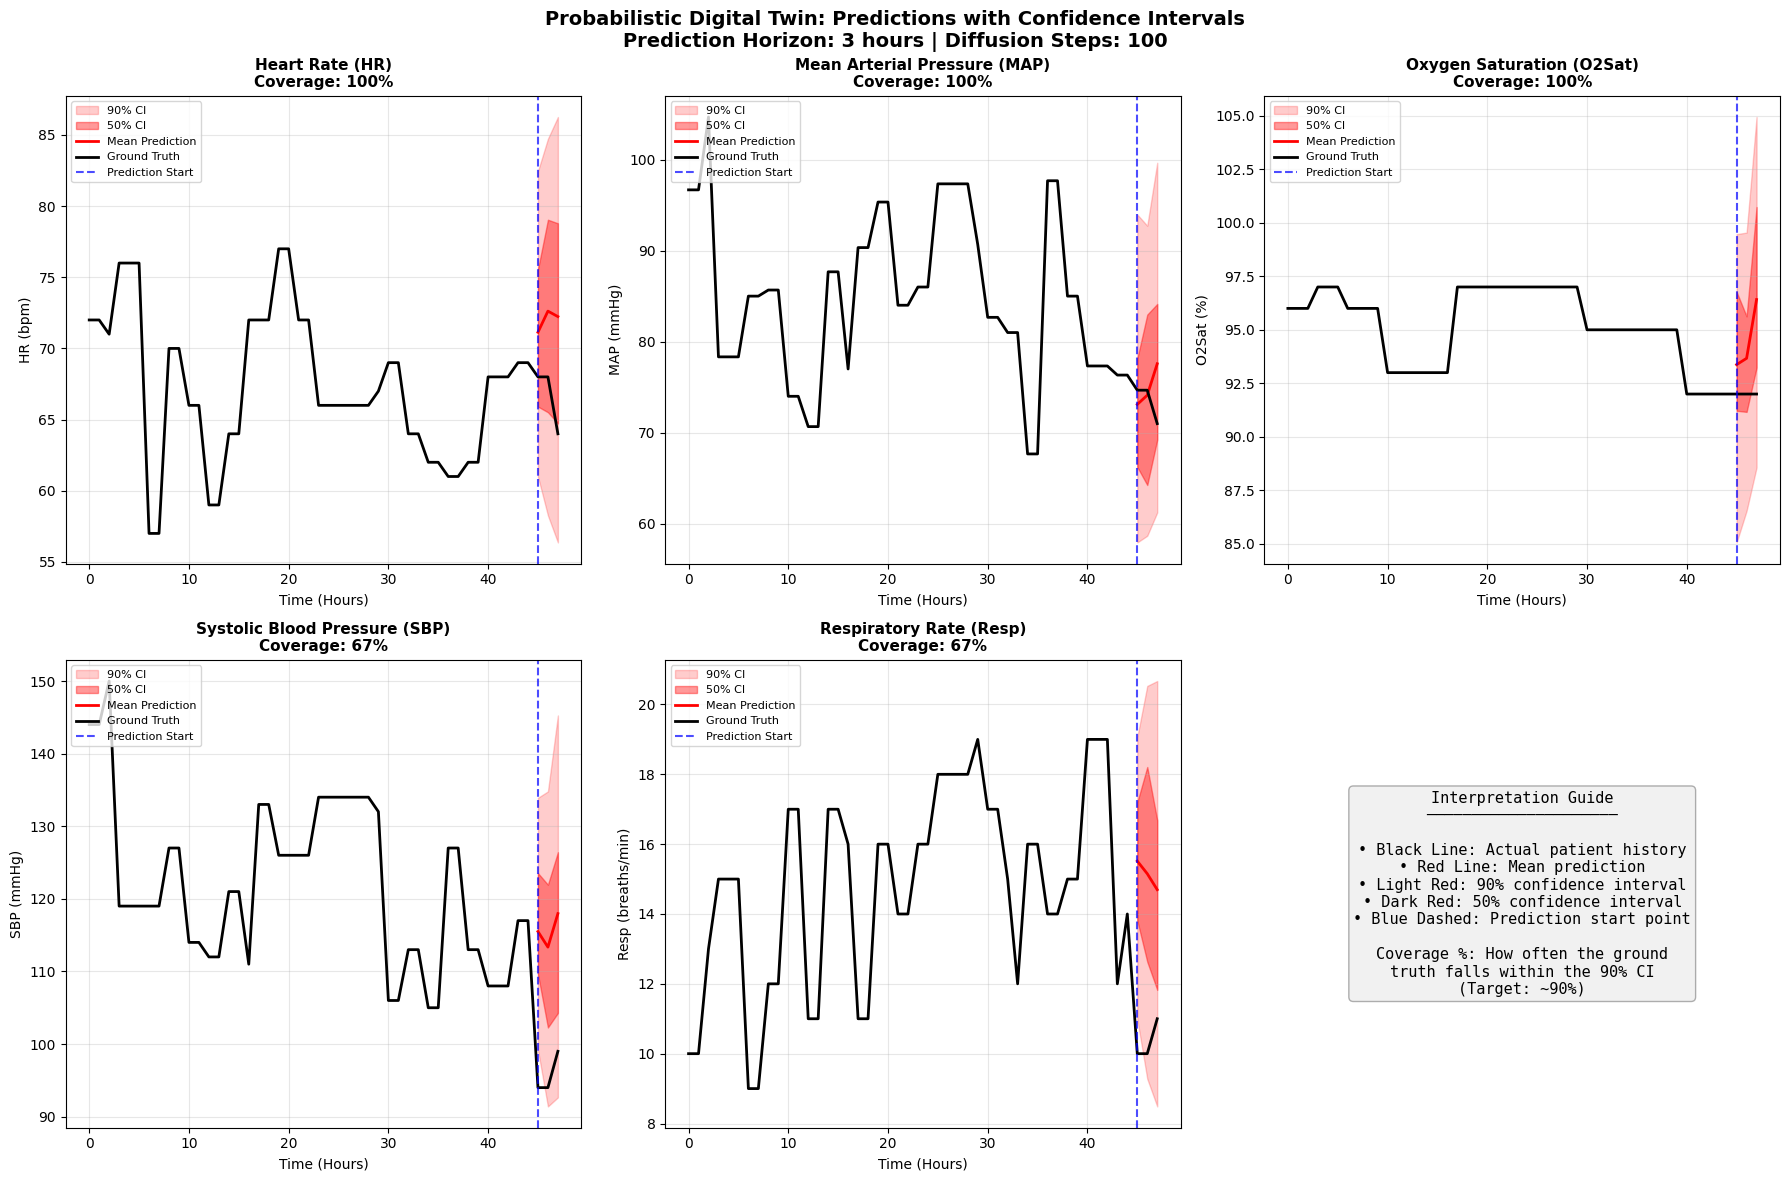

In [5]:
# ==========================================
# 7. Visualization with Confidence Intervals
# ==========================================

def plot_with_confidence_intervals(patient_sample, futures, save_fig=False):
    """
    Enhanced visualization showing mean prediction with confidence intervals.
    """
    split_pt = CONFIG["SEQ_LEN"] - CONFIG["PRED_LEN"]
    
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    axes = axes.flatten()
    
    for vital_idx, vital_key in enumerate(CONFIG["VITALS"]):
        ax = axes[vital_idx]
        info = VITAL_INFO[vital_key]
        scale_factor = info['scale']
        
        # Get predictions for this vital
        preds = futures[:, vital_idx, :] * scale_factor  # (50, T)
        truth = patient_sample[vital_idx].numpy() * scale_factor
        
        # Calculate statistics
        pred_mean = preds.mean(axis=0)
        pred_std = preds.std(axis=0)
        pred_5 = np.percentile(preds, 5, axis=0)
        pred_25 = np.percentile(preds, 25, axis=0)
        pred_75 = np.percentile(preds, 75, axis=0)
        pred_95 = np.percentile(preds, 95, axis=0)
        
        time_range = np.arange(CONFIG["SEQ_LEN"])
        
        # Plot 90% CI (lighter)
        ax.fill_between(time_range[split_pt:], 
                        pred_5[split_pt:], pred_95[split_pt:],
                        alpha=0.2, color='red', label='90% CI')
        
        # Plot 50% CI (darker)
        ax.fill_between(time_range[split_pt:], 
                        pred_25[split_pt:], pred_75[split_pt:],
                        alpha=0.4, color='red', label='50% CI')
        
        # Plot mean prediction
        ax.plot(time_range[split_pt:], pred_mean[split_pt:], 
                color='red', linewidth=2, label='Mean Prediction')
        
        # Plot Ground Truth
        ax.plot(time_range, truth, color='black', linewidth=2, label='Ground Truth')
        
        # Prediction start line
        ax.axvline(x=split_pt, color='blue', linestyle='--', alpha=0.7, label='Prediction Start')
        
        # Check if ground truth is within 90% CI
        future_truth = truth[split_pt:]
        future_5 = pred_5[split_pt:]
        future_95 = pred_95[split_pt:]
        coverage = ((future_truth >= future_5) & (future_truth <= future_95)).mean() * 100
        
        # Labels
        ax.set_title(f"{info['name']} ({vital_key})\nCoverage: {coverage:.0f}%", 
                     fontsize=11, fontweight='bold')
        ax.set_xlabel("Time (Hours)")
        ax.set_ylabel(f"{vital_key} ({info['unit']})")
        ax.legend(loc='upper left', fontsize=8)
        ax.grid(True, alpha=0.3)
    
    # Info panel in 6th subplot
    axes[5].axis('off')
    info_text = (
        "Interpretation Guide\n"
        "─────────────────────\n\n"
        "• Black Line: Actual patient history\n"
        "• Red Line: Mean prediction\n"
        "• Light Red: 90% confidence interval\n"
        "• Dark Red: 50% confidence interval\n"
        "• Blue Dashed: Prediction start point\n\n"
        "Coverage %: How often the ground\n"
        "truth falls within the 90% CI\n"
        "(Target: ~90%)"
    )
    axes[5].text(0.5, 0.5, info_text, fontsize=11, ha='center', va='center',
                 transform=axes[5].transAxes, family='monospace',
                 bbox=dict(boxstyle='round', facecolor='lightgray', alpha=0.3))
    
    plt.suptitle("Probabilistic Digital Twin: Predictions with Confidence Intervals\n"
                 f"Prediction Horizon: {CONFIG['PRED_LEN']} hours | Diffusion Steps: {CONFIG['DIFFUSION_STEPS']}", 
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    
    if save_fig:
        plt.savefig('digital_twin_predictions.png', dpi=150, bbox_inches='tight')
        print("📊 Figure saved as 'digital_twin_predictions.png'")
    
    plt.show()

# Generate new visualization with confidence intervals
print("\n📊 Generating enhanced visualization with confidence intervals...")
plot_with_confidence_intervals(patient_sample, futures, save_fig=False)


🔬 Comparing Sepsis vs Non-Sepsis Patients
   Available: 679 sepsis, 613 non-sepsis windows


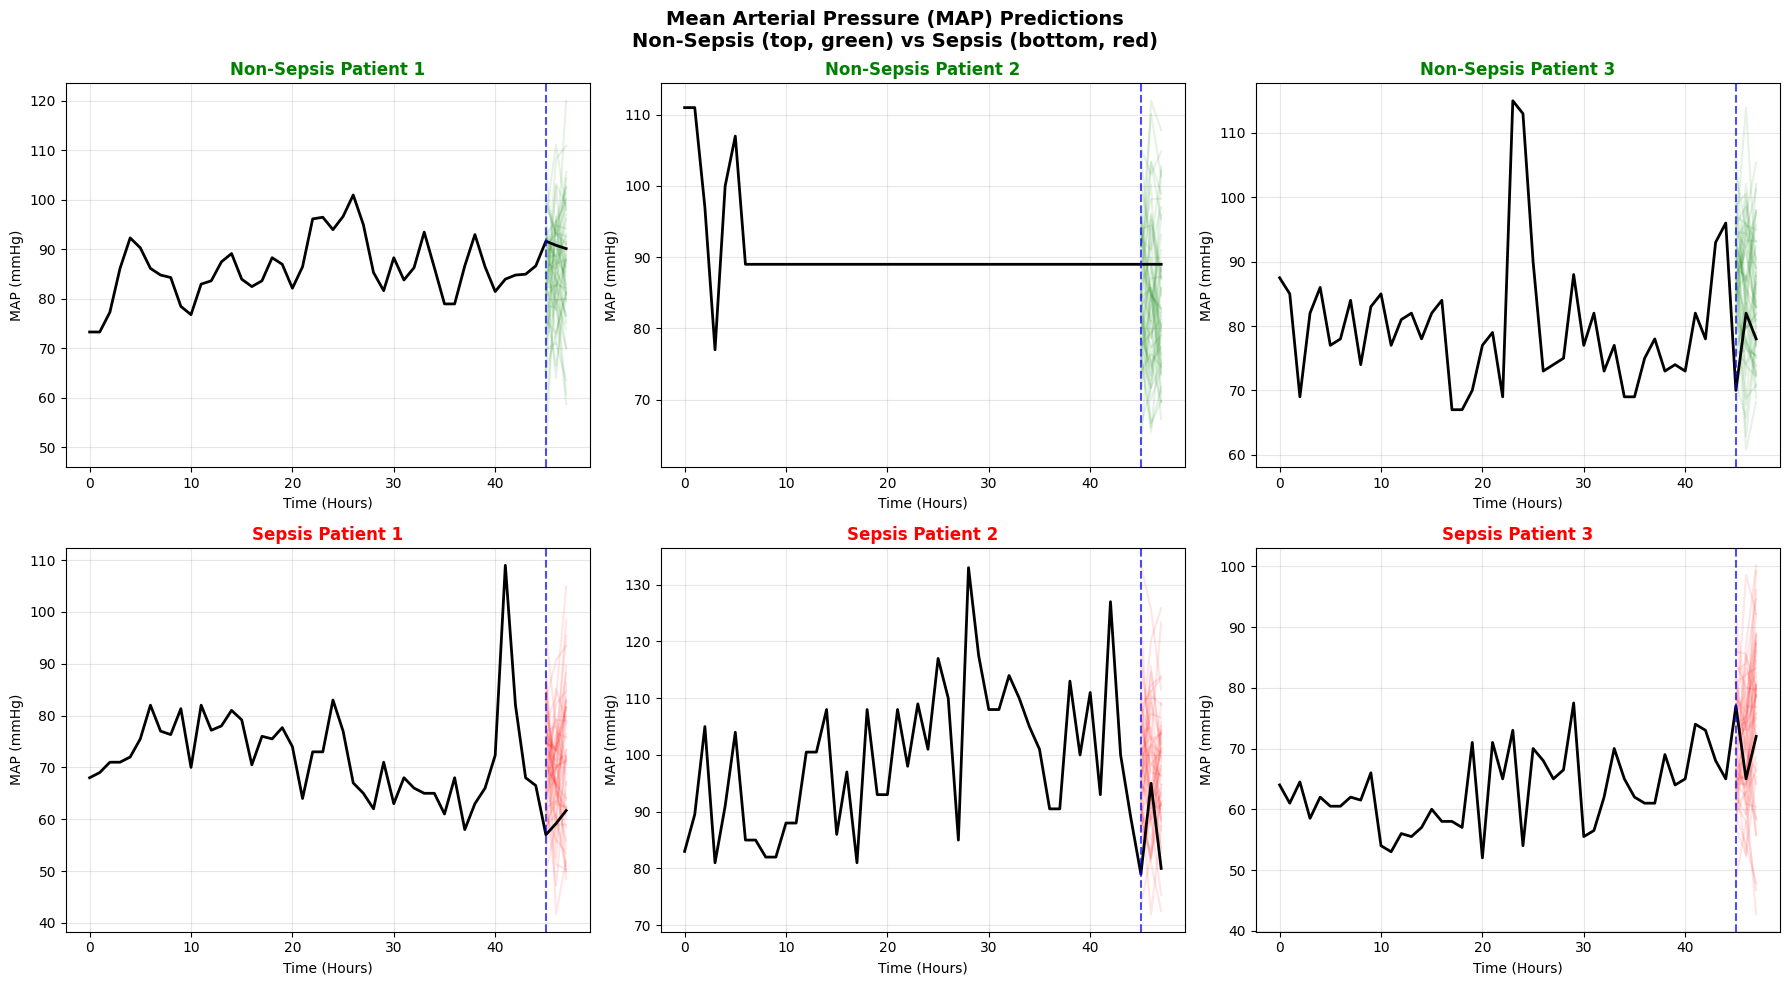


✓ Observation: Sepsis patients often show wider uncertainty and
  more volatile predictions due to physiological instability.


In [6]:
# ==========================================
# 8. Compare Multiple Patients (Sepsis vs Non-Sepsis)
# ==========================================

def compare_sepsis_vs_nonsepsis(model, dataset, device, n_samples=3):
    """
    Compare predictions for sepsis vs non-sepsis patients.
    """
    # Find sepsis and non-sepsis indices
    sepsis_indices = np.where(dataset.sepsis_flags == True)[0]
    nonsepsis_indices = np.where(dataset.sepsis_flags == False)[0]
    
    print(f"\n🔬 Comparing Sepsis vs Non-Sepsis Patients")
    print(f"   Available: {len(sepsis_indices)} sepsis, {len(nonsepsis_indices)} non-sepsis windows")
    
    # Sample from each group
    sepsis_samples = np.random.choice(sepsis_indices, min(n_samples, len(sepsis_indices)), replace=False)
    nonsepsis_samples = np.random.choice(nonsepsis_indices, min(n_samples, len(nonsepsis_indices)), replace=False)
    
    fig, axes = plt.subplots(2, n_samples, figsize=(6*n_samples, 10))
    
    vital_idx = 1  # MAP - often most indicative of sepsis
    vital_key = CONFIG["VITALS"][vital_idx]
    scale_factor = VITAL_INFO[vital_key]['scale']
    split_pt = CONFIG["SEQ_LEN"] - CONFIG["PRED_LEN"]
    
    # Plot non-sepsis patients
    for i, idx in enumerate(nonsepsis_samples):
        ax = axes[0, i]
        patient_sample = dataset[idx]
        futures = generate_digital_twin(model, patient_sample, device)
        
        preds = futures[:, vital_idx, :] * scale_factor
        truth = patient_sample[vital_idx].numpy() * scale_factor
        
        # Plot trajectories
        for j in range(50):
            ax.plot(range(split_pt, CONFIG["SEQ_LEN"]), 
                    preds[j, split_pt:], color='green', alpha=0.1)
        ax.plot(range(CONFIG["SEQ_LEN"]), truth, color='black', linewidth=2)
        ax.axvline(x=split_pt, color='blue', linestyle='--', alpha=0.7)
        
        ax.set_title(f"Non-Sepsis Patient {i+1}", fontweight='bold', color='green')
        ax.set_xlabel("Time (Hours)")
        ax.set_ylabel(f"MAP (mmHg)")
        ax.grid(True, alpha=0.3)
    
    # Plot sepsis patients
    for i, idx in enumerate(sepsis_samples):
        ax = axes[1, i]
        patient_sample = dataset[idx]
        futures = generate_digital_twin(model, patient_sample, device)
        
        preds = futures[:, vital_idx, :] * scale_factor
        truth = patient_sample[vital_idx].numpy() * scale_factor
        
        # Plot trajectories
        for j in range(50):
            ax.plot(range(split_pt, CONFIG["SEQ_LEN"]), 
                    preds[j, split_pt:], color='red', alpha=0.1)
        ax.plot(range(CONFIG["SEQ_LEN"]), truth, color='black', linewidth=2)
        ax.axvline(x=split_pt, color='blue', linestyle='--', alpha=0.7)
        
        ax.set_title(f"Sepsis Patient {i+1}", fontweight='bold', color='red')
        ax.set_xlabel("Time (Hours)")
        ax.set_ylabel(f"MAP (mmHg)")
        ax.grid(True, alpha=0.3)
    
    plt.suptitle(f"Mean Arterial Pressure (MAP) Predictions\nNon-Sepsis (top, green) vs Sepsis (bottom, red)", 
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    print("\n✓ Observation: Sepsis patients often show wider uncertainty and")
    print("  more volatile predictions due to physiological instability.")

# Run comparison
compare_sepsis_vs_nonsepsis(model, dataset, device, n_samples=3)


📊 EXTENDED EVALUATION: LONG-STAY PATIENTS
🔍 Searching for patients with stays > 60 hours...
   Found 10 patients with long stays
   1. p001646.psv: 279 hours (🔴 Sepsis)
   2. p001895.psv: 265 hours (🔴 Sepsis)
   3. p000009.psv: 258 hours (🔴 Sepsis)
   4. p000587.psv: 254 hours (🔴 Sepsis)
   5. p000541.psv: 251 hours (🔴 Sepsis)
   6. p002316.psv: 235 hours (🔴 Sepsis)
   7. p002211.psv: 229 hours (🔴 Sepsis)
   8. p002100.psv: 226 hours (🔴 Sepsis)
   9. p001610.psv: 225 hours (🔴 Sepsis)
   10. p002881.psv: 223 hours (🔴 Sepsis)

──────────────────────────────────────────────────────────────────────
📋 Patient 1/10: p001646.psv
   Stay length: 279 hours
   Found 10 patients with long stays
   1. p001646.psv: 279 hours (🔴 Sepsis)
   2. p001895.psv: 265 hours (🔴 Sepsis)
   3. p000009.psv: 258 hours (🔴 Sepsis)
   4. p000587.psv: 254 hours (🔴 Sepsis)
   5. p000541.psv: 251 hours (🔴 Sepsis)
   6. p002316.psv: 235 hours (🔴 Sepsis)
   7. p002211.psv: 229 hours (🔴 Sepsis)
   8. p002100.psv: 226 hou

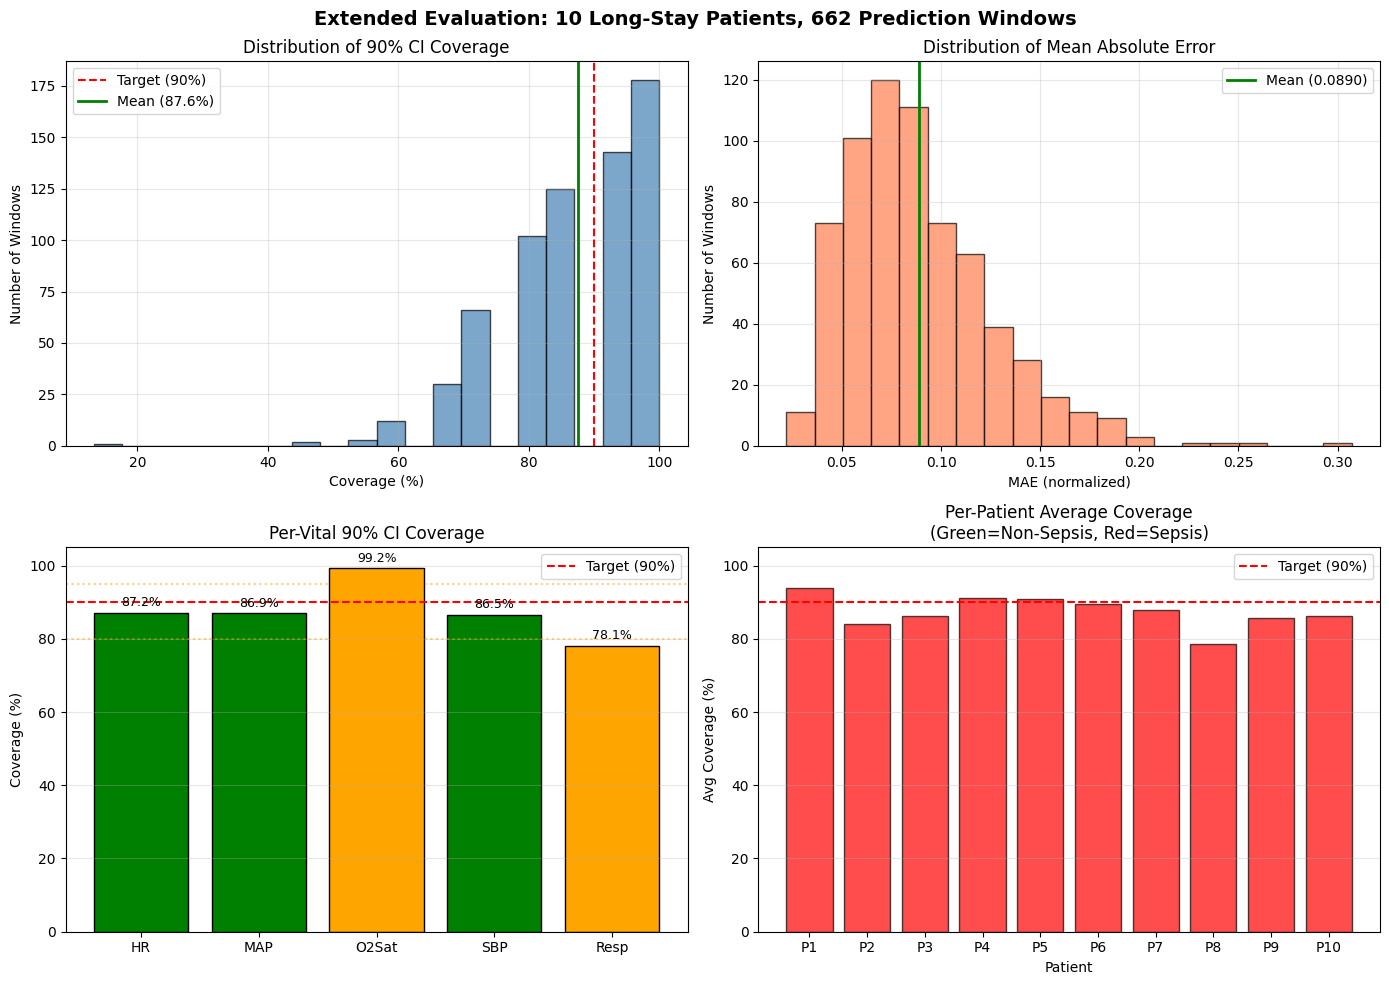


✓ Extended evaluation complete!
  Evaluated 662 prediction windows across 10 patients


In [7]:
# ==========================================
# 9. Extended Evaluation: Long-Stay Patients
# ==========================================
"""
Find patients with stays longer than 48 hours and evaluate the model
on multiple 3-hour prediction windows throughout their stay.
This provides a more robust evaluation of the model's performance.
"""

def find_long_stay_patients(data_dir, config, min_hours=60, max_patients=10):
    """
    Find patients with stays longer than min_hours.
    Returns list of (filename, dataframe, length) tuples.
    """
    files = sorted([f for f in os.listdir(data_dir) if f.endswith('.psv')])
    long_stay_patients = []
    
    print(f"🔍 Searching for patients with stays > {min_hours} hours...")
    
    for f in files[:config["MAX_FILES"]]:
        df = pd.read_csv(os.path.join(data_dir, f), sep='|')
        stay_length = len(df)
        
        if stay_length >= min_hours:
            has_sepsis = df['SepsisLabel'].max() == 1 if 'SepsisLabel' in df.columns else False
            long_stay_patients.append({
                'filename': f,
                'length': stay_length,
                'has_sepsis': has_sepsis
            })
    
    # Sort by length (longest first) and take top N
    long_stay_patients = sorted(long_stay_patients, key=lambda x: x['length'], reverse=True)
    long_stay_patients = long_stay_patients[:max_patients]
    
    print(f"   Found {len(long_stay_patients)} patients with long stays")
    for i, p in enumerate(long_stay_patients):
        sepsis_str = "🔴 Sepsis" if p['has_sepsis'] else "🟢 Non-sepsis"
        print(f"   {i+1}. {p['filename']}: {p['length']} hours ({sepsis_str})")
    
    return long_stay_patients


def prepare_patient_data(filename, data_dir, config):
    """
    Load and preprocess a single patient's full data.
    """
    df = pd.read_csv(os.path.join(data_dir, filename), sep='|')
    
    # Get sepsis label
    has_sepsis = df['SepsisLabel'].max() == 1 if 'SepsisLabel' in df.columns else False
    
    # Select vitals
    df = df[config["VITALS"]]
    
    # Handle missing data
    df = df.ffill().bfill().fillna(0)
    
    # Normalize
    norm_vals = {'HR': 100, 'MAP': 100, 'O2Sat': 100, 'SBP': 140, 'Resp': 20}
    for v in config["VITALS"]:
        df[v] = df[v] / norm_vals[v]
    
    return df.values.astype(np.float32), has_sepsis


def evaluate_long_stay_patient(model, patient_data, device, config, window_stride=3):
    """
    Evaluate model on multiple prediction windows for a single long-stay patient.
    
    Args:
        patient_data: Full patient data array (T, C)
        window_stride: How often to make predictions (every N hours)
    
    Returns:
        Dictionary with per-window and aggregate metrics
    """
    seq_len = config["SEQ_LEN"]
    pred_len = config["PRED_LEN"]
    total_hours = len(patient_data)
    
    # We need at least seq_len hours of history + pred_len hours of future
    max_start = total_hours - seq_len
    
    window_results = []
    
    # Evaluate at every window_stride hours starting from hour 48
    for start_hour in range(0, max_start + 1, window_stride):
        # Extract the window
        window = patient_data[start_hour : start_hour + seq_len]  # (seq_len, C)
        window_tensor = torch.tensor(window).transpose(0, 1)  # (C, seq_len)
        
        # Generate predictions
        futures = generate_digital_twin(model, window_tensor, device)  # (50, C, seq_len)
        
        # Ground truth for prediction window
        truth = window_tensor[:, -pred_len:].numpy()  # (C, pred_len)
        preds = futures[:, :, -pred_len:]  # (50, C, pred_len)
        
        # Calculate metrics
        mean_pred = preds.mean(axis=0)
        mae = np.abs(mean_pred - truth).mean()
        
        # 90% CI coverage
        lower = np.percentile(preds, 5, axis=0)
        upper = np.percentile(preds, 95, axis=0)
        coverage = ((truth >= lower) & (truth <= upper)).mean()
        
        # Interval width
        interval_width = (upper - lower).mean()
        
        # Per-vital metrics
        vital_metrics = {}
        for v_idx, v_name in enumerate(config["VITALS"]):
            v_mae = np.abs(mean_pred[v_idx] - truth[v_idx]).mean() * VITAL_INFO[v_name]['scale']
            v_coverage = ((truth[v_idx] >= lower[v_idx]) & (truth[v_idx] <= upper[v_idx])).mean()
            vital_metrics[v_name] = {'mae': v_mae, 'coverage': v_coverage}
        
        window_results.append({
            'start_hour': start_hour,
            'end_hour': start_hour + seq_len,
            'prediction_hours': f"{start_hour + seq_len - pred_len}-{start_hour + seq_len}",
            'mae': mae,
            'coverage': coverage,
            'interval_width': interval_width,
            'vital_metrics': vital_metrics
        })
    
    return window_results


def run_extended_evaluation(model, device, n_patients=10):
    """
    Run comprehensive evaluation on long-stay patients with multiple windows.
    """
    print("\n" + "="*70)
    print("📊 EXTENDED EVALUATION: LONG-STAY PATIENTS")
    print("="*70)
    
    # Find long-stay patients
    long_stay_patients = find_long_stay_patients(
        CONFIG["DATA_PATH"], CONFIG, min_hours=60, max_patients=n_patients
    )
    
    if len(long_stay_patients) == 0:
        print("❌ No patients with stays > 60 hours found!")
        return None
    
    all_results = []
    patient_summaries = []
    
    for i, patient_info in enumerate(long_stay_patients):
        print(f"\n{'─'*70}")
        print(f"📋 Patient {i+1}/{len(long_stay_patients)}: {patient_info['filename']}")
        print(f"   Stay length: {patient_info['length']} hours")
        
        # Load patient data
        patient_data, has_sepsis = prepare_patient_data(
            patient_info['filename'], CONFIG["DATA_PATH"], CONFIG
        )
        
        # Evaluate on multiple windows
        window_results = evaluate_long_stay_patient(
            model, patient_data, device, CONFIG, window_stride=3
        )
        
        # Aggregate patient-level metrics
        patient_maes = [w['mae'] for w in window_results]
        patient_coverages = [w['coverage'] for w in window_results]
        
        print(f"   Windows evaluated: {len(window_results)}")
        print(f"   Avg MAE: {np.mean(patient_maes):.4f}")
        print(f"   Avg Coverage: {np.mean(patient_coverages)*100:.1f}%")
        
        patient_summaries.append({
            'filename': patient_info['filename'],
            'length': patient_info['length'],
            'has_sepsis': has_sepsis,
            'n_windows': len(window_results),
            'avg_mae': np.mean(patient_maes),
            'avg_coverage': np.mean(patient_coverages),
            'window_results': window_results
        })
        
        all_results.extend(window_results)
    
    # ==========================================
    # Aggregate Results
    # ==========================================
    print("\n" + "="*70)
    print("📊 AGGREGATE RESULTS ACROSS ALL WINDOWS")
    print("="*70)
    
    total_windows = len(all_results)
    overall_mae = np.mean([r['mae'] for r in all_results])
    overall_coverage = np.mean([r['coverage'] for r in all_results])
    overall_width = np.mean([r['interval_width'] for r in all_results])
    
    print(f"\n🎯 Overall Metrics ({total_windows} prediction windows):")
    print(f"   Mean Absolute Error (normalized): {overall_mae:.4f}")
    print(f"   90% Prediction Interval Coverage: {overall_coverage*100:.1f}%")
    print(f"   Average Interval Width:           {overall_width:.4f}")
    
    # Per-vital aggregate metrics
    print(f"\n📈 Per-Vital MAE (in original units):")
    for v_name in CONFIG["VITALS"]:
        v_maes = [r['vital_metrics'][v_name]['mae'] for r in all_results]
        unit = VITAL_INFO[v_name]['unit']
        print(f"   {v_name:6s}: {np.mean(v_maes):6.2f} {unit}")
    
    print(f"\n📊 Per-Vital Coverage (target: 90%):")
    for v_name in CONFIG["VITALS"]:
        v_coverages = [r['vital_metrics'][v_name]['coverage'] for r in all_results]
        cov = np.mean(v_coverages) * 100
        status = "✓" if 80 <= cov <= 95 else "⚠️"
        print(f"   {v_name:6s}: {cov:5.1f}% {status}")
    
    # ==========================================
    # Sepsis vs Non-Sepsis Comparison
    # ==========================================
    sepsis_patients = [p for p in patient_summaries if p['has_sepsis']]
    nonsepsis_patients = [p for p in patient_summaries if not p['has_sepsis']]
    
    if sepsis_patients and nonsepsis_patients:
        print(f"\n📊 Sepsis vs Non-Sepsis Comparison:")
        sepsis_mae = np.mean([p['avg_mae'] for p in sepsis_patients])
        sepsis_cov = np.mean([p['avg_coverage'] for p in sepsis_patients])
        nonsepsis_mae = np.mean([p['avg_mae'] for p in nonsepsis_patients])
        nonsepsis_cov = np.mean([p['avg_coverage'] for p in nonsepsis_patients])
        
        print(f"   Non-Sepsis ({len(nonsepsis_patients)} patients): MAE={nonsepsis_mae:.4f}, Coverage={nonsepsis_cov*100:.1f}%")
        print(f"   Sepsis ({len(sepsis_patients)} patients):     MAE={sepsis_mae:.4f}, Coverage={sepsis_cov*100:.1f}%")
    
    # ==========================================
    # Visualization: Coverage over Time
    # ==========================================
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    # Plot 1: Coverage distribution
    ax1 = axes[0, 0]
    coverages = [r['coverage'] * 100 for r in all_results]
    ax1.hist(coverages, bins=20, edgecolor='black', alpha=0.7, color='steelblue')
    ax1.axvline(x=90, color='red', linestyle='--', label='Target (90%)')
    ax1.axvline(x=np.mean(coverages), color='green', linestyle='-', linewidth=2, label=f'Mean ({np.mean(coverages):.1f}%)')
    ax1.set_xlabel('Coverage (%)')
    ax1.set_ylabel('Number of Windows')
    ax1.set_title('Distribution of 90% CI Coverage')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # Plot 2: MAE distribution
    ax2 = axes[0, 1]
    maes = [r['mae'] for r in all_results]
    ax2.hist(maes, bins=20, edgecolor='black', alpha=0.7, color='coral')
    ax2.axvline(x=np.mean(maes), color='green', linestyle='-', linewidth=2, label=f'Mean ({np.mean(maes):.4f})')
    ax2.set_xlabel('MAE (normalized)')
    ax2.set_ylabel('Number of Windows')
    ax2.set_title('Distribution of Mean Absolute Error')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    # Plot 3: Per-vital coverage comparison
    ax3 = axes[1, 0]
    vital_names = CONFIG["VITALS"]
    vital_coverages_avg = []
    for v_name in vital_names:
        v_coverages = [r['vital_metrics'][v_name]['coverage'] * 100 for r in all_results]
        vital_coverages_avg.append(np.mean(v_coverages))
    
    colors = ['green' if 80 <= c <= 95 else 'orange' for c in vital_coverages_avg]
    bars = ax3.bar(vital_names, vital_coverages_avg, color=colors, edgecolor='black')
    ax3.axhline(y=90, color='red', linestyle='--', label='Target (90%)')
    ax3.axhline(y=80, color='orange', linestyle=':', alpha=0.5)
    ax3.axhline(y=95, color='orange', linestyle=':', alpha=0.5)
    ax3.set_ylabel('Coverage (%)')
    ax3.set_title('Per-Vital 90% CI Coverage')
    ax3.set_ylim(0, 105)
    ax3.legend()
    ax3.grid(True, alpha=0.3, axis='y')
    
    # Add value labels on bars
    for bar, val in zip(bars, vital_coverages_avg):
        ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, 
                f'{val:.1f}%', ha='center', va='bottom', fontsize=9)
    
    # Plot 4: Patient-level summary
    ax4 = axes[1, 1]
    patient_names = [f"P{i+1}" for i in range(len(patient_summaries))]
    patient_coverages = [p['avg_coverage'] * 100 for p in patient_summaries]
    patient_colors = ['red' if p['has_sepsis'] else 'green' for p in patient_summaries]
    
    bars = ax4.bar(patient_names, patient_coverages, color=patient_colors, edgecolor='black', alpha=0.7)
    ax4.axhline(y=90, color='red', linestyle='--', label='Target (90%)')
    ax4.set_ylabel('Avg Coverage (%)')
    ax4.set_xlabel('Patient')
    ax4.set_title('Per-Patient Average Coverage\n(Green=Non-Sepsis, Red=Sepsis)')
    ax4.set_ylim(0, 105)
    ax4.legend()
    ax4.grid(True, alpha=0.3, axis='y')
    
    plt.suptitle(f'Extended Evaluation: {len(patient_summaries)} Long-Stay Patients, {total_windows} Prediction Windows',
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    print(f"\n✓ Extended evaluation complete!")
    print(f"  Evaluated {total_windows} prediction windows across {len(patient_summaries)} patients")
    
    return {
        'patient_summaries': patient_summaries,
        'all_results': all_results,
        'overall_mae': overall_mae,
        'overall_coverage': overall_coverage
    }


# Run the extended evaluation
extended_metrics = run_extended_evaluation(model, device, n_patients=10)


🚨 CRITICAL EVENT (CRASH) PREDICTION ANALYSIS
🔍 Searching for patients with critical events (crashes)...
   Found 165 patients with critical events

📋 Top Critical Events Found:
   1. p001744.psv: Tachypnea at hour 54
      Resp: 15.3 → 35.0 (128.3% change)
      Sepsis: Yes 🔴
   2. p000042.psv: Tachypnea at hour 69
      Resp: 14.6 → 31.0 (112.3% change)
      Sepsis: Yes 🔴
   3. p002125.psv: Tachycardia at hour 87
      HR: 57.8 → 121.5 (110.1% change)
      Sepsis: Yes 🔴
   4. p001849.psv: Tachypnea at hour 62
      Resp: 15.3 → 32.0 (108.7% change)
      Sepsis: Yes 🔴
   5. p000178.psv: Tachypnea at hour 77
      Resp: 15.8 → 32.0 (103.2% change)
      Sepsis: Yes 🔴

📊 ANALYZING: Tachypnea Event
   Patient: p001744.psv
   Stay length: 123 hours
   Crash vital: Resp
   Crash hour: 54
   Value change: 15.3 → 35.0
   Severity: 128.3% change
   Sepsis: Yes 🔴

   Showing 6 consecutive prediction windows:
   - 6 windows BEFORE crash
   - 1 window AT crash
   - 3 windows AFTER crash


/tmp/ipython-input-3875712484.py:370: UserWarning: Glyph 128680 (\N{POLICE CARS REVOLVING LIGHT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128680 (\N{POLICE CARS REVOLVING LIGHT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


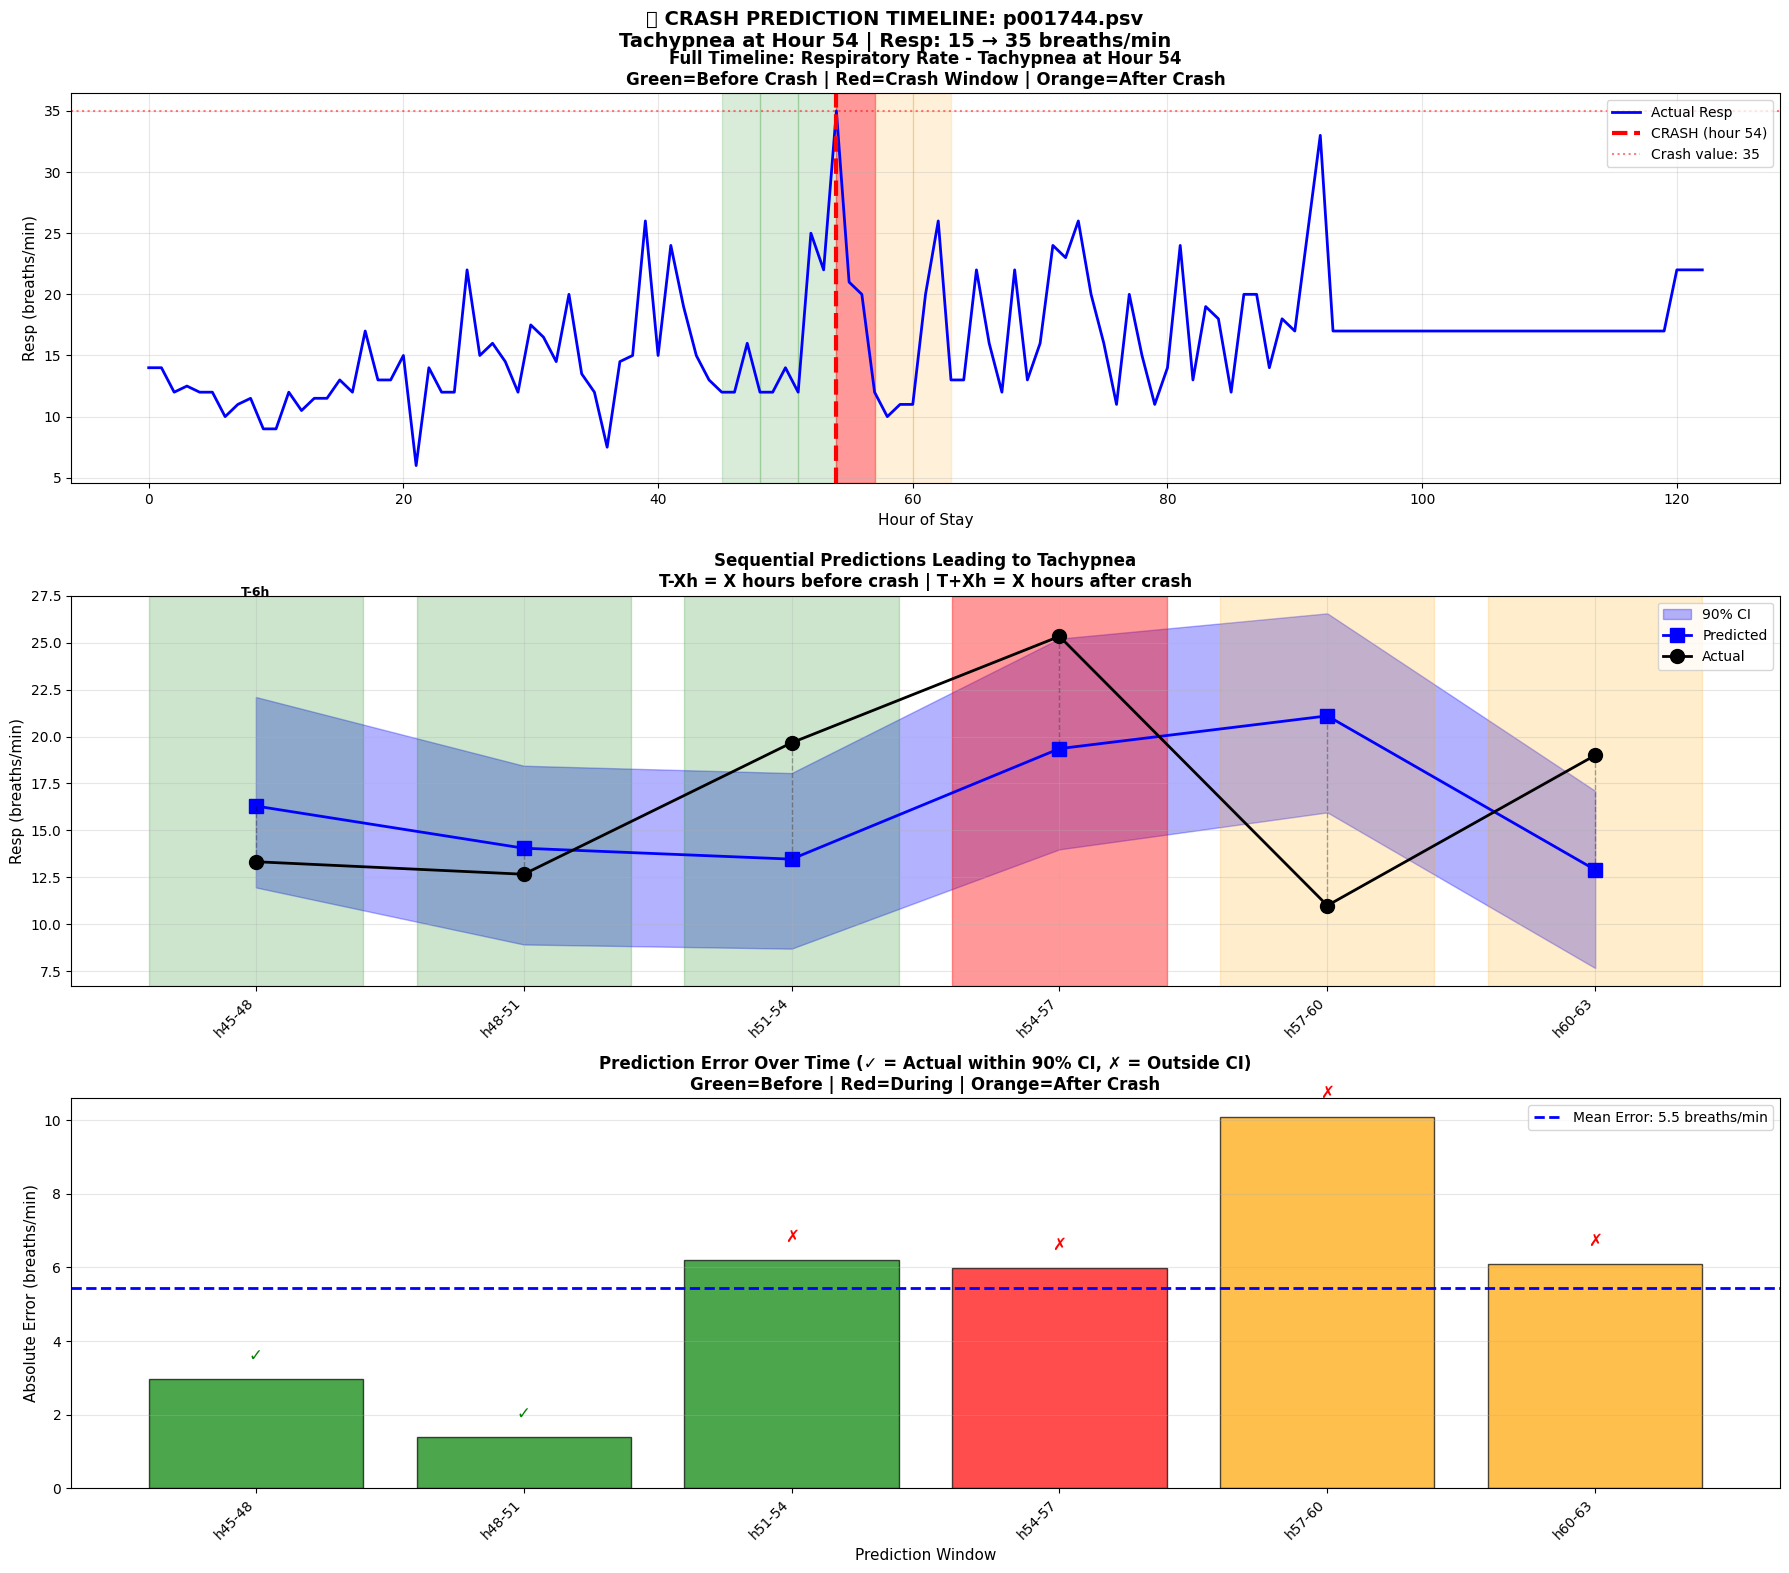


📊 DETAILED PREDICTION TIMELINE

Window       Timing     Hours    Predicted    Actual       Error      In 90% CI 
------------------------------------------------------------------------------------------
    h45-48   BEFORE     T-6h           16.3        13.3       3.0  ✅ YES     
    h48-51   BEFORE     T-3h           14.1        12.7       1.4  ✅ YES     
    h51-54   BEFORE     T-0h           13.5        19.7       6.2  ❌ NO      
>>> h54-57   CRASH      T=0            19.4        25.3       6.0  ❌ NO       <<<
    h57-60   AFTER      T+3h           21.1        11.0      10.1  ❌ NO      
    h60-63   AFTER      T+6h           12.9        19.0       6.1  ❌ NO      
------------------------------------------------------------------------------------------

📈 SUMMARY BY PHASE:
   BEFORE crash (3 windows): Avg Error = 3.5 breaths/min, Avg Coverage = 93.3%
   DURING crash (1 windows): Avg Error = 6.0 breaths/min, Avg Coverage = 80.0%
   AFTER crash (2 windows):  Avg Error = 8.1 breaths/

In [10]:
# ==========================================
# 10. Critical Event (Crash) Prediction Analysis
# ==========================================
"""
Find a patient who experienced a critical event (crash) such as:
- MAP dropping below 65 mmHg (hypotension)
- O2Sat dropping below 90% (hypoxemia)
- HR spike above 120 bpm (tachycardia)

Then evaluate how well the model predicted the crash BEFORE it happened.
Shows ALL consecutive predictions leading up to, during, and after the crash.
"""

def find_patient_with_crash(data_dir, config, min_hours=60):
    """
    Find patients who experienced a critical vital sign crash.
    Returns patient info with crash details.
    """
    files = sorted([f for f in os.listdir(data_dir) if f.endswith('.psv')])
    crash_patients = []
    
    print("🔍 Searching for patients with critical events (crashes)...")
    
    # Crash thresholds (in original units)
    CRASH_THRESHOLDS = {
        'MAP': {'type': 'below', 'threshold': 65, 'name': 'Hypotension'},
        'O2Sat': {'type': 'below', 'threshold': 90, 'name': 'Hypoxemia'},
        'HR': {'type': 'above', 'threshold': 120, 'name': 'Tachycardia'},
        'SBP': {'type': 'below', 'threshold': 90, 'name': 'Hypotension (SBP)'},
        'Resp': {'type': 'above', 'threshold': 30, 'name': 'Tachypnea'}
    }
    
    for f in files[:config["MAX_FILES"]]:
        df = pd.read_csv(os.path.join(data_dir, f), sep='|')
        
        if len(df) < min_hours:
            continue
        
        has_sepsis = df['SepsisLabel'].max() == 1 if 'SepsisLabel' in df.columns else False
        
        # Check for crashes in each vital
        for vital, crash_info in CRASH_THRESHOLDS.items():
            if vital not in df.columns:
                continue
                
            vital_data = df[vital].dropna()
            if len(vital_data) == 0:
                continue
            
            # Find crash points
            if crash_info['type'] == 'below':
                crash_indices = vital_data[vital_data < crash_info['threshold']].index.tolist()
            else:
                crash_indices = vital_data[vital_data > crash_info['threshold']].index.tolist()
            
            # We want crashes that happen AFTER hour 48 (so we have history to predict from)
            valid_crashes = [idx for idx in crash_indices if idx >= 48]
            
            if valid_crashes:
                # Find the first crash
                first_crash_hour = min(valid_crashes)
                crash_value = df.loc[first_crash_hour, vital]
                
                # Check if there's a significant change (not just baseline low/high)
                pre_crash_mean = df[vital].iloc[max(0, first_crash_hour-12):first_crash_hour].mean()
                
                if crash_info['type'] == 'below':
                    severity = (pre_crash_mean - crash_value) / pre_crash_mean * 100 if pre_crash_mean > 0 else 0
                else:
                    severity = (crash_value - pre_crash_mean) / pre_crash_mean * 100 if pre_crash_mean > 0 else 0
                
                # Only include if there's a meaningful change (>10%)
                if severity > 10:
                    crash_patients.append({
                        'filename': f,
                        'length': len(df),
                        'has_sepsis': has_sepsis,
                        'crash_vital': vital,
                        'crash_type': crash_info['name'],
                        'crash_hour': first_crash_hour,
                        'crash_value': crash_value,
                        'pre_crash_mean': pre_crash_mean,
                        'severity': severity
                    })
    
    # Sort by severity (most severe first)
    crash_patients = sorted(crash_patients, key=lambda x: x['severity'], reverse=True)
    
    print(f"   Found {len(crash_patients)} patients with critical events")
    
    return crash_patients


def evaluate_crash_prediction(model, device, windows_before=6, windows_after=3):
    """
    Evaluate model's ability to predict a critical crash event.
    Shows ALL consecutive predictions leading up to the crash.
    
    Args:
        windows_before: Number of 3-hour windows to show BEFORE the crash (default: 6 = 18 hours)
        windows_after: Number of 3-hour windows to show AFTER the crash (default: 3 = 9 hours)
    """
    print("\n" + "="*70)
    print("🚨 CRITICAL EVENT (CRASH) PREDICTION ANALYSIS")
    print("="*70)
    
    # Find patients with crashes
    crash_patients = find_patient_with_crash(CONFIG["DATA_PATH"], CONFIG, min_hours=60)
    
    if len(crash_patients) == 0:
        print("❌ No patients with critical events found!")
        return None
    
    # Show top crash candidates
    print(f"\n📋 Top Critical Events Found:")
    for i, p in enumerate(crash_patients[:5]):
        print(f"   {i+1}. {p['filename']}: {p['crash_type']} at hour {p['crash_hour']}")
        print(f"      {p['crash_vital']}: {p['pre_crash_mean']:.1f} → {p['crash_value']:.1f} ({p['severity']:.1f}% change)")
        print(f"      Sepsis: {'Yes 🔴' if p['has_sepsis'] else 'No 🟢'}")
    
    # Select the most severe crash
    patient_info = crash_patients[0]
    print(f"\n{'='*70}")
    print(f"📊 ANALYZING: {patient_info['crash_type']} Event")
    print(f"{'='*70}")
    print(f"   Patient: {patient_info['filename']}")
    print(f"   Stay length: {patient_info['length']} hours")
    print(f"   Crash vital: {patient_info['crash_vital']}")
    print(f"   Crash hour: {patient_info['crash_hour']}")
    print(f"   Value change: {patient_info['pre_crash_mean']:.1f} → {patient_info['crash_value']:.1f}")
    print(f"   Severity: {patient_info['severity']:.1f}% change")
    print(f"   Sepsis: {'Yes 🔴' if patient_info['has_sepsis'] else 'No 🟢'}")
    
    # Load patient data
    patient_data, has_sepsis = prepare_patient_data(
        patient_info['filename'], CONFIG["DATA_PATH"], CONFIG
    )
    
    total_hours = len(patient_data)
    seq_len = CONFIG["SEQ_LEN"]
    pred_len = CONFIG["PRED_LEN"]
    crash_hour = patient_info['crash_hour']
    crash_vital = patient_info['crash_vital']
    crash_vital_idx = CONFIG["VITALS"].index(crash_vital)
    
    # ==========================================
    # Create CONSECUTIVE windows leading up to crash
    # ==========================================
    # Window that predicts INTO the crash hour
    crash_window_start = crash_hour - seq_len + 1  # This window's prediction ends just after crash
    
    # Calculate the window whose prediction ENDS at crash hour
    # If crash is at hour 60, and we predict 3 hours, we need window starting at 60-48+3-3 = 12
    # Actually: window starting at (crash_hour - seq_len) will predict hours (crash_hour - pred_len) to crash_hour
    
    # The window that predicts the crash hour as the LAST predicted hour
    window_ending_at_crash = crash_hour - seq_len
    
    # Generate consecutive windows: every 3 hours (matching pred_len)
    window_starts = []
    
    # Windows BEFORE crash (going backwards from crash)
    for i in range(windows_before, 0, -1):
        start = window_ending_at_crash - (i * pred_len)
        if start >= 0:
            window_starts.append(start)
    
    # Window that includes crash
    if window_ending_at_crash >= 0:
        window_starts.append(window_ending_at_crash)
    
    # Windows AFTER crash
    for i in range(1, windows_after + 1):
        start = window_ending_at_crash + (i * pred_len)
        if start + seq_len <= total_hours:
            window_starts.append(start)
    
    print(f"\n   Showing {len(window_starts)} consecutive prediction windows:")
    print(f"   - {windows_before} windows BEFORE crash")
    print(f"   - 1 window AT crash")
    print(f"   - {windows_after} windows AFTER crash")
    
    # Evaluate each window
    results = []
    for start_hour in window_starts:
        window = patient_data[start_hour : start_hour + seq_len]
        window_tensor = torch.tensor(window).transpose(0, 1)
        
        futures = generate_digital_twin(model, window_tensor, device)
        
        truth = window_tensor[:, -pred_len:].numpy()
        preds = futures[:, :, -pred_len:]
        mean_pred = preds.mean(axis=0)
        
        # 90% CI
        lower = np.percentile(preds, 5, axis=0)
        upper = np.percentile(preds, 95, axis=0)
        coverage = ((truth >= lower) & (truth <= upper)).mean()
        
        # Check timing relative to crash
        pred_start_hour = start_hour + seq_len - pred_len
        pred_end_hour = start_hour + seq_len
        
        # Determine relationship to crash
        if pred_end_hour <= crash_hour:
            timing = "BEFORE"
            hours_to_crash = crash_hour - pred_end_hour
        elif pred_start_hour <= crash_hour <= pred_end_hour:
            timing = "CRASH"
            hours_to_crash = 0
        else:
            timing = "AFTER"
            hours_to_crash = pred_start_hour - crash_hour
        
        results.append({
            'start_hour': start_hour,
            'pred_start': pred_start_hour,
            'pred_end': pred_end_hour,
            'pred_hours': f"h{pred_start_hour}-{pred_end_hour}",
            'timing': timing,
            'hours_to_crash': hours_to_crash,
            'truth': truth,
            'mean_pred': mean_pred,
            'lower': lower,
            'upper': upper,
            'coverage': coverage,
            'all_preds': preds  # Keep all 50 samples for visualization
        })
    
    # ==========================================
    # Visualization
    # ==========================================
    crash_scale = VITAL_INFO[crash_vital]['scale']
    crash_unit = VITAL_INFO[crash_vital]['unit']
    
    fig, axes = plt.subplots(3, 1, figsize=(18, 16))
    
    # ===== Plot 1: Full timeline with prediction windows =====
    ax1 = axes[0]
    full_vital_data = patient_data[:, crash_vital_idx] * crash_scale
    time_range = np.arange(len(full_vital_data))
    
    ax1.plot(time_range, full_vital_data, 'b-', linewidth=2, label=f'Actual {crash_vital}')
    ax1.axvline(x=crash_hour, color='red', linestyle='--', linewidth=3, label=f'CRASH (hour {crash_hour})')
    ax1.axhline(y=patient_info['crash_value'], color='red', linestyle=':', alpha=0.5, 
                label=f'Crash value: {patient_info["crash_value"]:.0f}')
    
    # Shade prediction windows with labels
    for i, r in enumerate(results):
        if r['timing'] == 'BEFORE':
            color = 'green'
            alpha = 0.15
        elif r['timing'] == 'CRASH':
            color = 'red'
            alpha = 0.4
        else:
            color = 'orange'
            alpha = 0.15
        ax1.axvspan(r['pred_start'], r['pred_end'], alpha=alpha, color=color)
    
    ax1.set_xlabel('Hour of Stay', fontsize=11)
    ax1.set_ylabel(f'{crash_vital} ({crash_unit})', fontsize=11)
    ax1.set_title(f"Full Timeline: {VITAL_INFO[crash_vital]['name']} - {patient_info['crash_type']} at Hour {crash_hour}\n"
                  f"Green=Before Crash | Red=Crash Window | Orange=After Crash",
                  fontsize=12, fontweight='bold')
    ax1.legend(loc='upper right')
    ax1.grid(True, alpha=0.3)
    
    # ===== Plot 2: Consecutive predictions with timing labels =====
    ax2 = axes[1]
    x_positions = np.arange(len(results))
    
    actual_vals = []
    pred_vals = []
    pred_lowers = []
    pred_uppers = []
    
    for r in results:
        actual_vals.append(r['truth'][crash_vital_idx].mean() * crash_scale)
        pred_vals.append(r['mean_pred'][crash_vital_idx].mean() * crash_scale)
        pred_lowers.append(r['lower'][crash_vital_idx].mean() * crash_scale)
        pred_uppers.append(r['upper'][crash_vital_idx].mean() * crash_scale)
    
    actual_vals = np.array(actual_vals)
    pred_vals = np.array(pred_vals)
    pred_lowers = np.array(pred_lowers)
    pred_uppers = np.array(pred_uppers)
    
    # Plot confidence interval
    ax2.fill_between(x_positions, pred_lowers, pred_uppers, 
                     alpha=0.3, color='blue', label='90% CI')
    
    # Plot predicted
    ax2.plot(x_positions, pred_vals, 'bs-', markersize=10, linewidth=2, label='Predicted')
    
    # Plot actual
    ax2.plot(x_positions, actual_vals, 'ko-', markersize=10, linewidth=2, label='Actual')
    
    # Color bars by timing and add labels
    for i, r in enumerate(results):
        # Background color
        if r['timing'] == 'BEFORE':
            ax2.axvspan(i-0.4, i+0.4, alpha=0.2, color='green')
            label = f"T-{r['hours_to_crash']}h"
        elif r['timing'] == 'CRASH':
            ax2.axvspan(i-0.4, i+0.4, alpha=0.4, color='red')
            label = "CRASH!"
        else:
            ax2.axvspan(i-0.4, i+0.4, alpha=0.2, color='orange')
            label = f"T+{r['hours_to_crash']}h"
        
        # Add timing label at top
        ax2.annotate(label, (i, ax2.get_ylim()[1] if i == 0 else max(pred_uppers) + 5), 
                    ha='center', fontsize=9, fontweight='bold',
                    color='red' if r['timing'] == 'CRASH' else 'black')
        
        # Connect predicted to actual
        ax2.plot([i, i], [actual_vals[i], pred_vals[i]], 'k--', alpha=0.3, linewidth=1)
    
    ax2.set_ylabel(f'{crash_vital} ({crash_unit})', fontsize=11)
    ax2.set_title(f"Sequential Predictions Leading to {patient_info['crash_type']}\n"
                  f"T-Xh = X hours before crash | T+Xh = X hours after crash",
                  fontsize=12, fontweight='bold')
    ax2.legend(loc='upper right')
    ax2.grid(True, alpha=0.3)
    ax2.set_xticks(x_positions)
    ax2.set_xticklabels([r['pred_hours'] for r in results], rotation=45, ha='right')
    
    # ===== Plot 3: Prediction error over time =====
    ax3 = axes[2]
    
    errors = np.abs(pred_vals - actual_vals)
    within_ci = [pred_lowers[i] <= actual_vals[i] <= pred_uppers[i] for i in range(len(results))]
    
    # Bar colors based on timing
    bar_colors = []
    for r in results:
        if r['timing'] == 'BEFORE':
            bar_colors.append('green')
        elif r['timing'] == 'CRASH':
            bar_colors.append('red')
        else:
            bar_colors.append('orange')
    
    bars = ax3.bar(x_positions, errors, color=bar_colors, edgecolor='black', alpha=0.7)
    
    # Mark whether actual was within CI
    for i, (in_ci, err) in enumerate(zip(within_ci, errors)):
        marker = '✓' if in_ci else '✗'
        color = 'green' if in_ci else 'red'
        ax3.annotate(marker, (i, err + 0.5), ha='center', fontsize=12, color=color, fontweight='bold')
    
    ax3.axhline(y=np.mean(errors), color='blue', linestyle='--', linewidth=2, 
                label=f'Mean Error: {np.mean(errors):.1f} {crash_unit}')
    
    ax3.set_xlabel('Prediction Window', fontsize=11)
    ax3.set_ylabel(f'Absolute Error ({crash_unit})', fontsize=11)
    ax3.set_title(f"Prediction Error Over Time (✓ = Actual within 90% CI, ✗ = Outside CI)\n"
                  f"Green=Before | Red=During | Orange=After Crash",
                  fontsize=12, fontweight='bold')
    ax3.legend(loc='upper right')
    ax3.grid(True, alpha=0.3, axis='y')
    ax3.set_xticks(x_positions)
    ax3.set_xticklabels([r['pred_hours'] for r in results], rotation=45, ha='right')
    
    plt.suptitle(f"🚨 CRASH PREDICTION TIMELINE: {patient_info['filename']}\n"
                 f"{patient_info['crash_type']} at Hour {crash_hour} | "
                 f"{crash_vital}: {patient_info['pre_crash_mean']:.0f} → {patient_info['crash_value']:.0f} {crash_unit}",
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # ==========================================
    # Detailed Summary Table
    # ==========================================
    print("\n" + "="*90)
    print("📊 DETAILED PREDICTION TIMELINE")
    print("="*90)
    print(f"\n{'Window':<12} {'Timing':<10} {'Hours':<8} {'Predicted':<12} {'Actual':<12} {'Error':<10} {'In 90% CI':<10}")
    print("-" * 90)
    
    for r in results:
        pred = r['mean_pred'][crash_vital_idx].mean() * crash_scale
        actual = r['truth'][crash_vital_idx].mean() * crash_scale
        lower = r['lower'][crash_vital_idx].mean() * crash_scale
        upper = r['upper'][crash_vital_idx].mean() * crash_scale
        error = abs(pred - actual)
        in_ci = lower <= actual <= upper
        
        timing_str = r['timing']
        if r['timing'] == 'BEFORE':
            hours_str = f"T-{r['hours_to_crash']}h"
        elif r['timing'] == 'CRASH':
            hours_str = "T=0"
        else:
            hours_str = f"T+{r['hours_to_crash']}h"
        
        ci_str = "✅ YES" if in_ci else "❌ NO"
        
        # Highlight crash row
        if r['timing'] == 'CRASH':
            print(f">>> {r['pred_hours']:<8} {timing_str:<10} {hours_str:<8} {pred:>10.1f}  {actual:>10.1f}  {error:>8.1f}  {ci_str:<10} <<<")
        else:
            print(f"    {r['pred_hours']:<8} {timing_str:<10} {hours_str:<8} {pred:>10.1f}  {actual:>10.1f}  {error:>8.1f}  {ci_str:<10}")
    
    print("-" * 90)
    
    # Summary statistics
    before_results = [r for r in results if r['timing'] == 'BEFORE']
    crash_results = [r for r in results if r['timing'] == 'CRASH']
    after_results = [r for r in results if r['timing'] == 'AFTER']
    
    print(f"\n📈 SUMMARY BY PHASE:")
    
    if before_results:
        before_errors = [abs(r['mean_pred'][crash_vital_idx].mean() - r['truth'][crash_vital_idx].mean()) * crash_scale 
                        for r in before_results]
        before_coverages = [r['coverage'] for r in before_results]
        print(f"   BEFORE crash ({len(before_results)} windows): Avg Error = {np.mean(before_errors):.1f} {crash_unit}, Avg Coverage = {np.mean(before_coverages)*100:.1f}%")
    
    if crash_results:
        crash_errors = [abs(r['mean_pred'][crash_vital_idx].mean() - r['truth'][crash_vital_idx].mean()) * crash_scale 
                       for r in crash_results]
        crash_coverages = [r['coverage'] for r in crash_results]
        print(f"   DURING crash ({len(crash_results)} windows): Avg Error = {np.mean(crash_errors):.1f} {crash_unit}, Avg Coverage = {np.mean(crash_coverages)*100:.1f}%")
    
    if after_results:
        after_errors = [abs(r['mean_pred'][crash_vital_idx].mean() - r['truth'][crash_vital_idx].mean()) * crash_scale 
                       for r in after_results]
        after_coverages = [r['coverage'] for r in after_results]
        print(f"   AFTER crash ({len(after_results)} windows):  Avg Error = {np.mean(after_errors):.1f} {crash_unit}, Avg Coverage = {np.mean(after_coverages)*100:.1f}%")
    
    # Did model anticipate crash?
    print(f"\n🔮 EARLY WARNING ANALYSIS:")
    print(f"   Pre-crash baseline: {patient_info['pre_crash_mean']:.1f} {crash_unit}")
    print(f"   Crash value:        {patient_info['crash_value']:.1f} {crash_unit}")
    
    if before_results:
        # Check if predictions were trending toward crash before it happened
        pred_trend = [r['mean_pred'][crash_vital_idx].mean() * crash_scale for r in before_results]
        
        if patient_info['crash_type'] in ['Hypotension', 'Hypotension (SBP)', 'Hypoxemia']:
            # For drops
            trending_down = pred_trend[-1] < pred_trend[0] if len(pred_trend) > 1 else False
            last_pred_below_baseline = pred_trend[-1] < patient_info['pre_crash_mean']
            print(f"\n   Model predictions before crash:")
            for i, (r, p) in enumerate(zip(before_results, pred_trend)):
                direction = "↓" if i > 0 and p < pred_trend[i-1] else "↑" if i > 0 and p > pred_trend[i-1] else "─"
                print(f"      {r['pred_hours']}: {p:.1f} {crash_unit} {direction}")
            
            if trending_down or last_pred_below_baseline:
                print(f"\n   ✅ Model showed EARLY WARNING signs (predicted lower values before crash)")
            else:
                print(f"\n   ⚠️ Model did NOT anticipate the decline")
        else:
            # For spikes
            trending_up = pred_trend[-1] > pred_trend[0] if len(pred_trend) > 1 else False
            last_pred_above_baseline = pred_trend[-1] > patient_info['pre_crash_mean']
            print(f"\n   Model predictions before crash:")
            for i, (r, p) in enumerate(zip(before_results, pred_trend)):
                direction = "↑" if i > 0 and p > pred_trend[i-1] else "↓" if i > 0 and p < pred_trend[i-1] else "─"
                print(f"      {r['pred_hours']}: {p:.1f} {crash_unit} {direction}")
            
            if trending_up or last_pred_above_baseline:
                print(f"\n   ✅ Model showed EARLY WARNING signs (predicted higher values before crash)")
            else:
                print(f"\n   ⚠️ Model did NOT anticipate the spike")
    
    print(f"\n✓ Crash prediction analysis complete!")
    
    return {
        'patient_info': patient_info,
        'results': results,
        'before_results': before_results,
        'crash_results': crash_results,
        'after_results': after_results
    }


# Run crash prediction analysis
# Shows 6 windows before crash (~18 hours), crash window, and 3 windows after (~9 hours)
crash_analysis = evaluate_crash_prediction(model, device, windows_before=6, windows_after=3)